# Exploratory Data Analysis (EDA)

## Objectives
The objective of EDA is to explore, summarise and visualise data to understand its main characteristics. This will allow us to identify appropriate modelling techniques.

## 1. Load Data
Below, I use Pandas functions to read the CSV files we have been given.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_train, load_test

train = load_train()
test = load_test()

## 2. Data Quality
We want to understand the data shape, column names, types, and whether there are missing values.

In [2]:
print("Training data shape:", train.shape)
print("Testing data shape:", test.shape, "\n")

# Confirm the missing column in the testing data is the target variable, SalePrice.
print(train.columns.difference(test.columns), "\n")

print("Training data dtypes:\n", train.dtypes.value_counts().to_frame().T, "\n")
print("Testing data dtypes:\n", test.dtypes.value_counts().to_frame().T, "\n")


train_nans = train.isnull().sum()[train.isnull().sum() > 0].index.tolist()
test_nans = test.isnull().sum()[test.isnull().sum() > 0].index.tolist()
print("Training data columns with NaNs:\n", train_nans, "\n")
print("Testing data columns with NaNs:\n", test_nans, "\n")

nans = set(train_nans).union(set(test_nans))
print("Columns we must handle:\n", nans, "\n")

Training data shape: (1460, 80)
Testing data shape: (1459, 79) 

Index(['SalePrice'], dtype='str') 

Training data dtypes:
        str  int64  float64
count   43     34        3 

Testing data dtypes:
        str  int64  float64
count   43     25       11 

Training data columns with NaNs:
 ['LotFrontage', 'Alley', 'MasVnrType', 'MasVnrArea', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature'] 

Testing data columns with NaNs:
 ['MSZoning', 'LotFrontage', 'Alley', 'Utilities', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',

### Uniqueness
Each house should be recorded once, and each `Id` should identify one house. A repeated row would count twice in a model, and a house in both train and test would make the test score look better than it is. We ask:
- Is any `Id` repeated, or shared between train and test?
- Is any row repeated within train or within test?
- Does a house appear in both train and test, or more than once with only the sale details changed?

In [3]:
# Are any Ids repeated, or shared between train and test? Id is the index.
print("Duplicated Ids: train", train.index.duplicated().sum(), ", test", test.index.duplicated().sum())
print("Ids in both train and test:", len(train.index.intersection(test.index)))
print("Id ranges: train", train.index.min(), "to", train.index.max(), ", test", test.index.min(), "to", test.index.max())

# Is any row repeated? Id is the index, so this compares every other column.
print("\nDuplicated rows: train", train.duplicated().sum(), ", test", test.duplicated().sum())

Duplicated Ids: train 0 , test 0
Ids in both train and test: 0
Id ranges: train 1 to 1460 , test 1461 to 2919

Duplicated rows: train 0 , test 0


##### Findings:
- Every `Id` is unique. Train uses Ids 1 to 1460 and test uses 1461 to 2919, with no overlap and no gaps.
- No row is repeated within train or within test.

##### Decision:
There is nothing to remove. No `Id` or row is repeated, and no house is in both train and test.

### Outliers
An outlier is a value, or a whole house, that is far from the rest. It is not necessarily an error: a very large house can be real, and expensive. What matters is whether it is consistent with the other columns, in particular the sale price, and whether it would distort a model. We use the interquartile range and plots against the sale price. Model-based diagnostics such as Cook's distance are only defined for regression models, so they are left for the modelling stage. We ask:
- Which values are extreme, and in which columns?
- Which houses are extreme in several ways at once?
- Are they consistent with the sale price?
- Does test contain houses beyond the range of train, where a model has to extrapolate?

Values beyond the fences, by column: {'LotArea': 34, 'MasVnrArea': 25, 'OpenPorchSF': 18, 'LotFrontage': 12, 'TotalBsmtSF': 5, 'GrLivArea': 4, 'GarageArea': 3, 'WoodDeckSF': 3} 

Share of houses with a value of 0: {'MasVnrArea': np.float64(0.59), 'OpenPorchSF': np.float64(0.45), 'WoodDeckSF': np.float64(0.52)} 



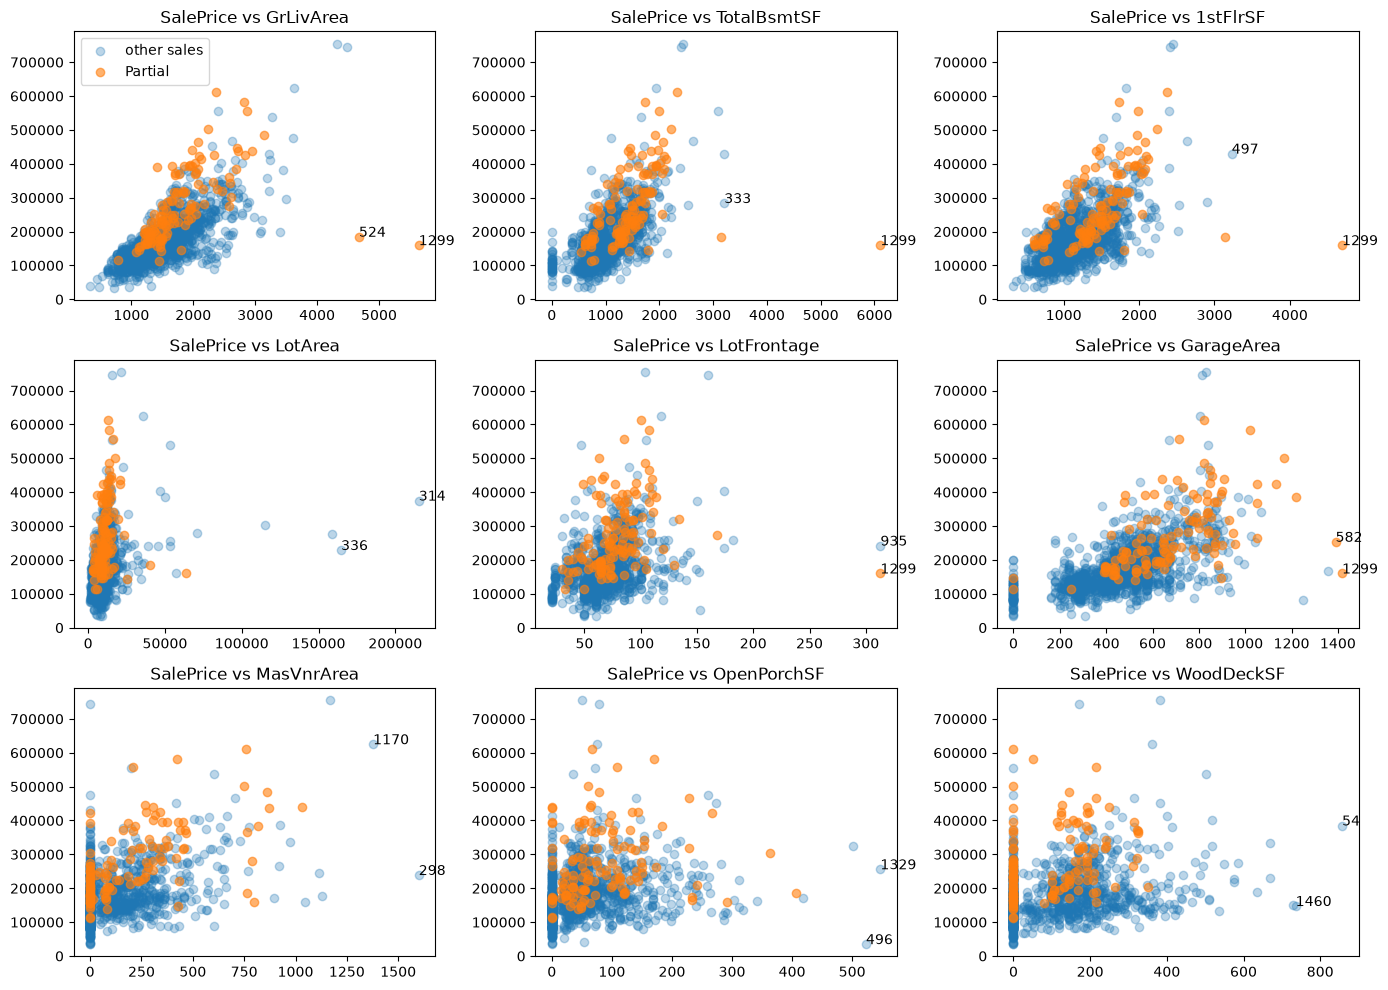

,GrLivArea,SalePrice,SaleCondition,YearBuilt,Neighborhood,OverallQual,ExtremeColumns
Id,,,,,,,
1299,5642,160000,Partial,2008,Edwards,10,7
524,4676,184750,Partial,2007,Edwards,10,5
692,4316,755000,Normal,1994,NoRidge,10,4


,GrLivArea,SalePrice,SaleCondition,YearBuilt,YrSold,Neighborhood,OverallQual
Id,,,,,,,
524,4676,184750,Partial,2007,2007,Edwards,10
692,4316,755000,Normal,1994,2007,NoRidge,10
1183,4476,745000,Abnorml,1996,2007,NoRidge,10
1299,5642,160000,Partial,2008,2008,Edwards,10


Median price per sq ft of living area: all sales 120.1 , Partial sales 148.8


In [4]:
# Univariate: how many values lie more than 3 interquartile ranges beyond the quartiles?
numeric = train.select_dtypes("number").drop(columns="SalePrice")
q1, q3 = numeric.quantile(0.25), numeric.quantile(0.75)
iqr = q3 - q1
beyond = ((numeric < q1 - 3 * iqr) | (numeric > q3 + 3 * iqr)).sum()[iqr > 0]
print("Values beyond the fences, by column:", beyond[beyond > 0].sort_values(ascending=False).head(8).to_dict(), "\n")
print("Share of houses with a value of 0:", {column: round((train[column] == 0).mean(), 2) for column in ["MasVnrArea", "OpenPorchSF", "WoodDeckSF"]}, "\n")

# Size against sale price. Partial sales (houses not complete at the time of the sale) are marked,
# and the two largest houses in each panel are labelled by Id.
columns = ["GrLivArea", "TotalBsmtSF", "1stFlrSF", "LotArea", "LotFrontage", "GarageArea", "MasVnrArea", "OpenPorchSF", "WoodDeckSF"]
partial = train["SaleCondition"] == "Partial"
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, column in zip(axes.flat, columns):
    ax.scatter(train.loc[~partial, column], train.loc[~partial, "SalePrice"], alpha=0.3, label="other sales")
    ax.scatter(train.loc[partial, column], train.loc[partial, "SalePrice"], alpha=0.6, color="tab:orange", label="Partial")
    for house in train[column].nlargest(2).index:
        ax.annotate(str(house), (train.loc[house, column], train.loc[house, "SalePrice"]))
    ax.set_title(f"SalePrice vs {column}")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

# Houses above the 99.5th percentile in at least 3 of these 10 size columns.
size_columns = ["LotFrontage", "LotArea", "MasVnrArea", "TotalBsmtSF", "1stFlrSF", "GrLivArea", "GarageArea", "BsmtFinSF1", "WoodDeckSF", "OpenPorchSF"]
n_extreme = (train[size_columns] > train[size_columns].quantile(0.995)).sum(axis=1)
display(
    train.loc[n_extreme[n_extreme >= 3].index, ["GrLivArea", "SalePrice", "SaleCondition", "YearBuilt", "Neighborhood", "OverallQual"]]
    .assign(ExtremeColumns=n_extreme)
    .sort_values("ExtremeColumns", ascending=False)
)

# The houses with a living area above 4000 sq ft.
display(train[train["GrLivArea"] > 4000][["GrLivArea", "SalePrice", "SaleCondition", "YearBuilt", "YrSold", "Neighborhood", "OverallQual"]])
print("Median price per sq ft of living area: all sales", round((train["SalePrice"] / train["GrLivArea"]).median(), 1), ", Partial sales", round((train.loc[partial, "SalePrice"] / train.loc[partial, "GrLivArea"]).median(), 1))

In [5]:
# Test houses above the largest value in train, where a model has to extrapolate.
ranges = size_columns + ["2ndFlrSF", "EnclosedPorch", "ScreenPorch", "PoolArea", "MiscVal"]
above = [
    {"Column": column, "Id": house, "Test value": test.loc[house, column], "Train maximum": train[column].max()}
    for column in ranges
    for house in test.index[test[column] > train[column].max()]
]
display(pd.DataFrame(above))

# The largest house in test.
display(test.loc[test["GrLivArea"] > 4000, ["GrLivArea", "1stFlrSF", "MiscVal", "SaleCondition", "YearBuilt", "YrSold", "Neighborhood", "OverallQual"]])

,Column,Id,Test value,Train maximum
0,1stFlrSF,2550,5095.0,4692
1,GarageArea,2072,1488.0,1418
2,WoodDeckSF,2607,1424.0,857
3,WoodDeckSF,2683,870.0,857
4,OpenPorchSF,2487,570.0,547
5,OpenPorchSF,2558,742.0,547
6,EnclosedPorch,2504,1012.0,552
7,EnclosedPorch,2568,584.0,552
8,ScreenPorch,1645,490.0,480
9,ScreenPorch,2153,576.0,480


,GrLivArea,1stFlrSF,MiscVal,SaleCondition,YearBuilt,YrSold,Neighborhood,OverallQual
Id,,,,,,,,
2550,5095,5095,17000,Partial,2008,2007,Edwards,10


##### Findings:
- Most extreme values are in the size columns. The number of train values more than 3 interquartile ranges beyond the quartiles is highest for `LotArea` (34), `MasVnrArea` (25), `OpenPorchSF` (18) and `LotFrontage` (12), and much lower for `TotalBsmtSF` (5) and `GrLivArea` (4).
- For living area, basement and first-floor size, the price rises with size and the large values mostly follow the trend, apart from the houses below. For `LotArea` it does not: the very largest lots (Ids 314 and 336, at over 160,000 sq ft) sold for ordinary prices, so price stops rising with lot size. These lots are extreme but plausible.
- The last three columns plotted are zero for about half the houses (59% of `MasVnrArea`, 45% of `OpenPorchSF` and 52% of `WoodDeckSF`), and show only a weak link with price. Their largest values are single houses with a very large veneer, porch or deck (Ids 298 and 1170, 1329 and 496, and 54 and 1460), priced ordinarily or low, and none of them is extreme in several columns. Id 496 is the cheapest house in train, an abnormal sale of 34,900 with a large porch.
- Two houses are extreme in several ways at once. Id 1299 is above the 99.5th percentile in 7 of the 10 size columns and Id 524 in 5, with living areas of 5,642 and 4,676 sq ft. They sold for only 160,000 and 184,750, which is far below the trend, and below the median price per square foot of other `Partial` sales.
- Both are `Partial` sales of houses built in the year they were sold (2008 and 2007), in `Edwards`, with `OverallQual` 10. A `Partial` sale is a house that was not complete when last assessed, so the price may not reflect the full house.
- Two other houses above 4,000 sq ft, Ids 692 and 1183, sold for 755,000 and 745,000. They are in `NoRidge` and priced in line with their size, so they are extreme but consistent.
- Test contains a house like Ids 1299 and 524. Id 2550 is a `Partial` sale in `Edwards`, built in 2008, with `OverallQual` 10 and a living area of 5,095 sq ft. Its `1stFlrSF` (5,095) and `MiscVal` (17,000) are above the largest values in train (4,692 and 15,500).
- A few other test values are beyond train: `WoodDeckSF`, `OpenPorchSF`, `EnclosedPorch` and `ScreenPorch` for 2 houses each, and `PoolArea` and `GarageArea` for 1. These are modest, but a linear model would extrapolate for them.

##### Decision:
Remove Ids 1299 and 524 from train, and keep every other row. We judge that these two sales do not represent the houses we want to predict, which are houses sold at the price of the house as measured.

Reasons:
- They are the most extreme houses in the data, and far from the trend in the plots.
- Their prices probably do not describe the houses as measured. Both are `Partial` sales of unfinished new builds, priced at about 28 and 40 per sq ft of living area, against a median of about 149 for all `Partial` sales.
- They are two rows (0.14% of train), so little information is lost.

We accept the risks set out above. In particular, Id 2550 in test looks like these two houses, so a model that has not seen them may price it high. It is the test house to check once the models are built.

What this means:
- The two houses are removed from `train` straight after this decision, so every section below uses the 1,458 remaining rows.
- `remove_outliers` in `src/features.py` does this using `OUTLIER_IDS`, and `clean` applies it too, so the fills never use statistics from these houses. Test houses are never removed.
- Ids 692 and 1183, the large lots and the other extreme values are consistent with their prices or with plausible houses, so they are kept.
- The effect of the removal, and model-based diagnostics such as Cook's distance, can be examined once the models are built.


In [6]:
from src.features import remove_outliers

train = remove_outliers(train)
print("Rows in train after removing the two outliers:", len(train))

Rows in train after removing the two outliers: 1458


### Missing Values

Many columns have NaNs, and they need different treatment. In some, a NaN means the feature is absent (for example, no basement). In others, the value is genuinely missing. We therefore go through the columns one at a time, starting with `LotFrontage`.

#### LotFrontage
`LotFrontage` is the length of street connected to the property, in feet. We ask:
- How much is missing, in train and in test?
- Is a NaN a zero frontage, or is the value genuinely missing?
- What do the observed values look like?
- How does it relate to lot size and lot type?
- Is it missing at random, or do the houses with a missing value differ?

Train: 259 missing (17.8%)
Test: 227 missing (15.6%)
Zeros in train: 0 

count    1199.0
mean       69.8
std        23.2
min        21.0
25%        59.0
50%        69.0
75%        80.0
max       313.0

skew: 1.54 
skew of log: -0.85


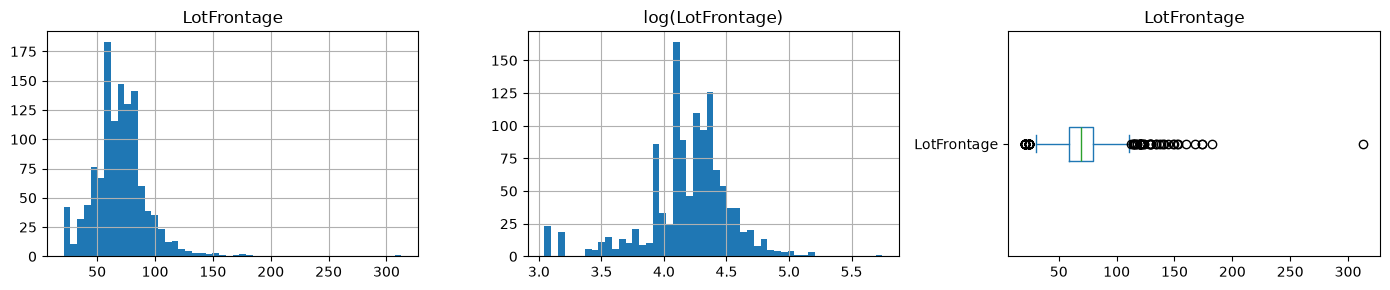

In [7]:
# How much is missing, and are any observed values zero?
for label, df in [("Train", train), ("Test", test)]:
    print(f"{label}: {df['LotFrontage'].isnull().sum()} missing ({df['LotFrontage'].isnull().mean():.1%})")
print("Zeros in train:", (train["LotFrontage"] == 0).sum(), "\n")

# Distribution of the observed values, on the raw and log scales.
observed = train["LotFrontage"].dropna()
print(observed.describe().round(1).to_string())
print("\nskew:", round(observed.skew(), 2), "\nskew of log:", round(np.log(observed).skew(), 2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
observed.hist(bins=50, ax=axes[0])
axes[0].set_title("LotFrontage")
np.log(observed).hist(bins=50, ax=axes[1])
axes[1].set_title("log(LotFrontage)")
observed.plot.box(vert=False, ax=axes[2])
axes[2].set_title("LotFrontage")
plt.tight_layout()
plt.show()

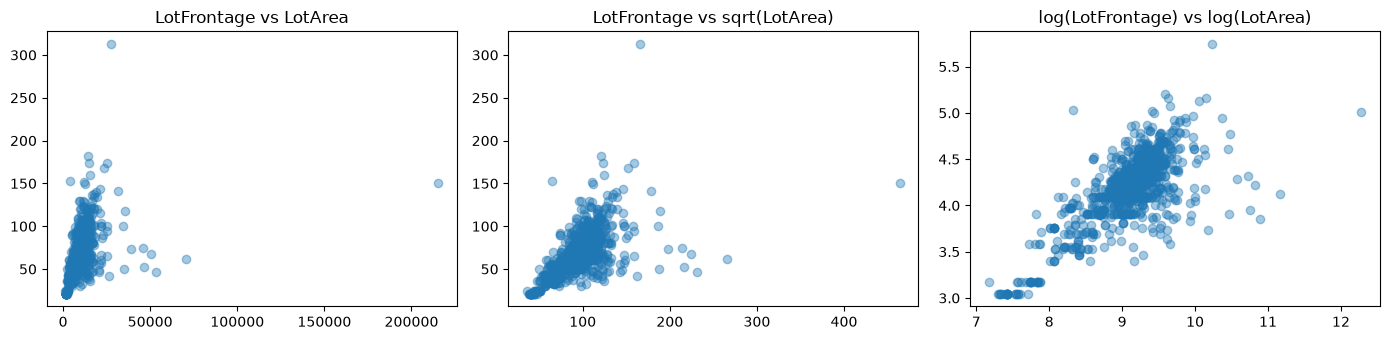

Correlation with LotFrontage:
LotArea: 0.39
sqrt(LotArea): 0.58
log-log: 0.74


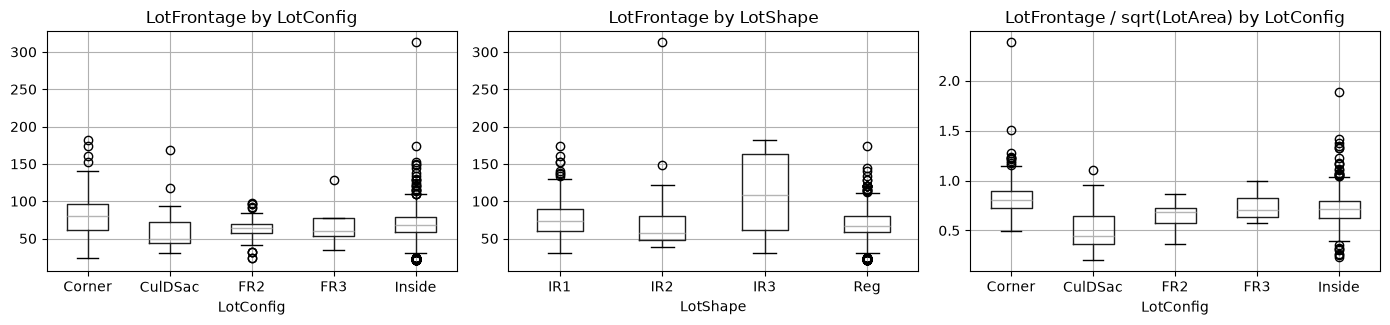

In [8]:
# Relationship with lot size, on the raw, square root and log-log scales.
lot = train[["LotFrontage", "LotArea"]].dropna()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].scatter(lot["LotArea"], lot["LotFrontage"], alpha=0.4)
axes[0].set_title("LotFrontage vs LotArea")
axes[1].scatter(np.sqrt(lot["LotArea"]), lot["LotFrontage"], alpha=0.4)
axes[1].set_title("LotFrontage vs sqrt(LotArea)")
axes[2].scatter(np.log(lot["LotArea"]), np.log(lot["LotFrontage"]), alpha=0.4)
axes[2].set_title("log(LotFrontage) vs log(LotArea)")
plt.tight_layout()
plt.show()

print("Correlation with LotFrontage:")
print(f"LotArea: {lot['LotFrontage'].corr(lot['LotArea']):.2f}")
print(f"sqrt(LotArea): {lot['LotFrontage'].corr(np.sqrt(lot['LotArea'])):.2f}")
print(f"log-log: {np.log(lot['LotFrontage']).corr(np.log(lot['LotArea'])):.2f}")

# Lot type: LotFrontage by LotConfig and LotShape, and frontage relative to lot size by LotConfig.
ratio = (train["LotFrontage"] / np.sqrt(train["LotArea"])).rename("ratio")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
train.boxplot("LotFrontage", by="LotConfig", ax=axes[0])
axes[0].set_title("LotFrontage by LotConfig")
train.boxplot("LotFrontage", by="LotShape", ax=axes[1])
axes[1].set_title("LotFrontage by LotShape")
pd.concat([ratio, train["LotConfig"]], axis=1).boxplot("ratio", by="LotConfig", ax=axes[2])
axes[2].set_title("LotFrontage / sqrt(LotArea) by LotConfig")
plt.suptitle("")
plt.tight_layout()
plt.show()

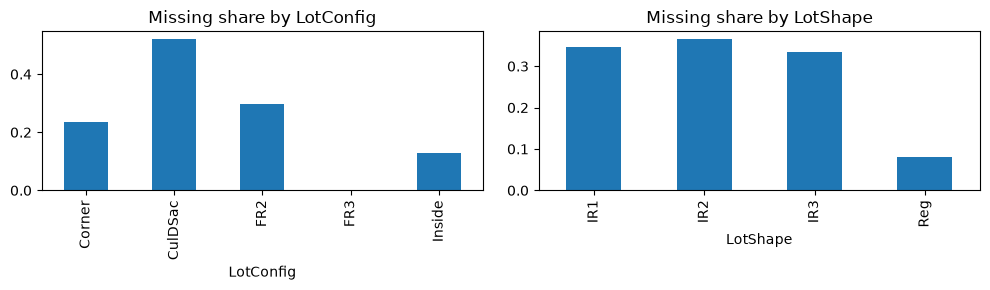

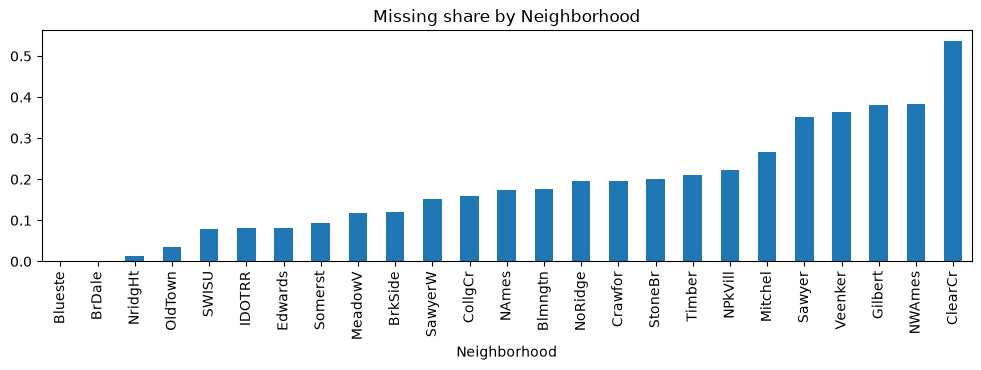

,LotArea,YearBuilt,GrLivArea,SalePrice
LotFrontage missing,,,,
False,9250.0,1972.0,1456.0,159434.0
True,10624.0,1976.0,1478.0,172400.0


,Train,Test
LotConfig,,
Corner,0.24,0.17
CulDSac,0.52,0.46
FR2,0.30,0.16
FR3,0.00,0.40
Inside,0.13,0.13


In [9]:
# Share of LotFrontage missing, by lot type and by neighbourhood (train).
missing = train["LotFrontage"].isnull()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
missing.groupby(train["LotConfig"]).mean().plot.bar(ax=axes[0], title="Missing share by LotConfig")
missing.groupby(train["LotShape"]).mean().plot.bar(ax=axes[1], title="Missing share by LotShape")
plt.tight_layout()
plt.show()

missing.groupby(train["Neighborhood"]).mean().sort_values().plot.bar(
    figsize=(12, 3), title="Missing share by Neighborhood"
)
plt.show()

# Do houses with a missing LotFrontage differ from the rest? Median of a few columns.
display(
    train.groupby(missing.rename("LotFrontage missing"))[["LotArea", "YearBuilt", "GrLivArea", "SalePrice"]].median()
)

# Is the pattern the same in test? Share missing by LotConfig.
share = pd.DataFrame(
    {
        "Train": train.groupby("LotConfig")["LotFrontage"].apply(lambda s: s.isnull().mean()),
        "Test": test.groupby("LotConfig")["LotFrontage"].apply(lambda s: s.isnull().mean()),
    }
)
display(share.round(2))

##### Findings:
- 259 houses (17.8%) in train and 227 (15.6%) in test are missing `LotFrontage`. No observed value is 0 (the minimum is 21 ft), so a NaN is genuinely missing and not a zero frontage.
- The observed values are right-skewed (skew 1.5). Most lie between 59 and 80 ft, with a small cluster at about 21 to 24 ft and a long tail up to 313 ft. The log scale removes the skew (the log skew is -0.85, slightly over-corrected).
- The 313 ft house (Id 935) is far above the trend for its lot size, so it is likely an outlier.
- Frontage grows with lot size, but not linearly. The correlation is 0.39 with `LotArea`, 0.58 with `sqrt(LotArea)` and 0.74 on log-log scales, where the relationship is closest to a straight line. Very large lots do not have proportionally large frontage.
- Lot type matters. Corner lots tend to have the widest frontage and cul-de-sac lots the narrowest, including relative to lot size.
- The values are not missing at random. Cul-de-sac lots are missing most often (52%), then `FR2` (30%) and corner lots (24%), against 13% of inside lots. Irregular lots (`IR1` to `IR3`) are missing 30% to 37% of the time, against 8% of regular lots.
- The missing share also varies widely by neighbourhood, from almost none in several of them to over half in `ClearCr` (54%).
- Houses with a missing value have somewhat larger lots (median 10,624 sq ft against 9,250), and are similar in year built, living area and sale price.
- Test follows the same pattern, with 46% of cul-de-sac lots missing against 13% of inside lots.
- Any fill should therefore use lot size and lot type, rather than a single value for every house.

##### Decision:
`LotFrontage` is filled with a linear regression on the log scale (regression imputation), implemented with scikit-learn in `src/features.py`. The model is

```
log(LotFrontage) = β0 + β1·log(LotArea) + β2·Corner + β3·CulDSac + β4·FR2 + β5·FR3 + β6·Townhouse
```

where `Corner`, `CulDSac`, `FR2` and `FR3` are 0/1 indicators for `LotConfig` (`Inside` is the baseline), and `Townhouse` is 1 when `BldgType` is `Twnhs` or `TwnhsE`.

Methodology:
- Fit the model on the train houses where `LotFrontage` is observed. Three extreme lots (Ids 935, 314 and 1338) are left out of the fit only, and stay in the data.
- Use the fitted coefficients to predict `log(LotFrontage)` for every missing house in train and test, then convert back with the exponential.
- Clip the predictions to the observed range of the fit data (21 to 182 ft), so that extreme lots are not extrapolated.
- Add a `LotFrontageMissing` flag, since missingness is related to lot type.
- Fit on train only and apply the same coefficients to test, so no test information is used.

Reasons:
- Frontage is right-skewed, and is closest to a straight line against lot area on log-log scales (correlation 0.74), so the model is fitted on the log scale. This also reduces the pull of extreme lots.
- Lot configuration and townhouses shift the level of frontage (about 30% lower for cul-de-sacs and 24% lower for townhouses), and these are also where values are most often missing. `LotShape` added nothing once `LotConfig` was included.
- The remaining scatter is about 0.20 on the log scale (roughly ±22% for an individual house), so the fill is approximate. Every filled house also gets its predicted value, so the filled values have less spread than real ones.

intercept: 0.257
log_lot_area    0.436
Corner          0.127
CulDSac        -0.361
FR2            -0.083
FR3             0.141
Townhouse      -0.279
clipped to: (np.float64(21.0), np.float64(182.0))

NaNs remaining (train, test): 0 0
       observed  filled
count    1199.0   259.0
mean       69.8    71.4
std        23.2    22.6
min        21.0    26.7
25%        59.0    59.0
50%        69.0    70.9
75%        80.0    82.2
max       313.0   182.0


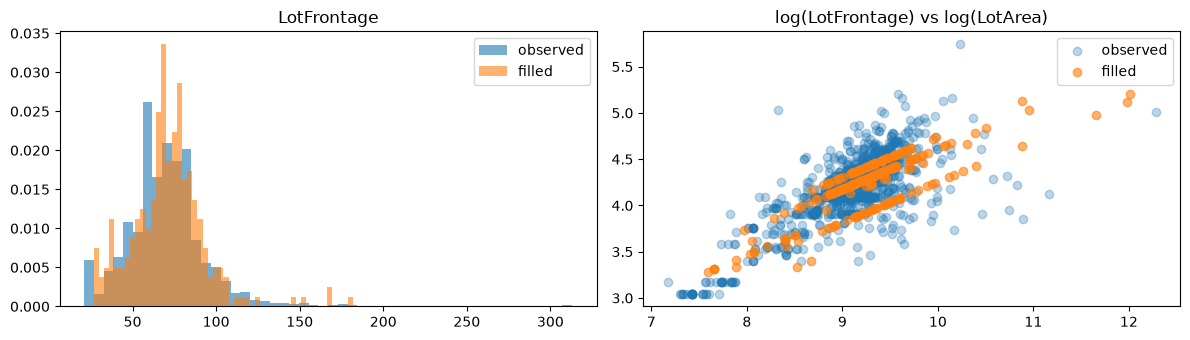

In [10]:
from src.features import fit_lot_frontage, fill_lot_frontage

# Fit on the observed train rows, then fill train and test with the same train model.
model, bounds = fit_lot_frontage(train)
train_filled = fill_lot_frontage(train, model, bounds)
test_filled = fill_lot_frontage(test, model, bounds)

# Fitted coefficients, and the range that predictions are clipped to.
print(f"intercept: {model.intercept_:.3f}")
print(pd.Series(model.coef_, index=model.feature_names_in_).round(3).to_string())
print("clipped to:", bounds)

# No NaNs should remain, and the filled values should look like the observed ones.
print("\nNaNs remaining (train, test):", train_filled["LotFrontage"].isnull().sum(), test_filled["LotFrontage"].isnull().sum())
filled = train_filled.loc[train["LotFrontage"].isnull(), "LotFrontage"]
observed = train["LotFrontage"].dropna()
print(pd.DataFrame({"observed": observed.describe(), "filled": filled.describe()}).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(observed, bins=50, alpha=0.6, density=True, label="observed")
axes[0].hist(filled, bins=50, alpha=0.6, density=True, label="filled")
axes[0].set_title("LotFrontage")
axes[0].legend()
axes[1].scatter(np.log(train.loc[observed.index, "LotArea"]), np.log(observed), alpha=0.3, label="observed")
axes[1].scatter(np.log(train.loc[filled.index, "LotArea"]), np.log(filled), alpha=0.6, label="filled")
axes[1].set_title("log(LotFrontage) vs log(LotArea)")
axes[1].legend()
plt.tight_layout()
plt.show()

#### MSZoning
`MSZoning` is the general zoning classification of the sale (for example `RL` for residential low density). We ask:
- How much is missing, in train and in test?
- How are the zones distributed?
- What predicts the zone, and can it be used for the missing houses?

          Train  Test
MSZoning             
C (all)      10    15
FV           65    74
RH           16    10
RL         1149  1114
RM          218   242
NaN           0     4 



,Neighborhood,MSSubClass,LotArea,BldgType,YearBuilt
Id,,,,,
1916,IDOTRR,30,21780,1Fam,1910
2217,IDOTRR,20,14584,1Fam,1952
2251,IDOTRR,70,56600,1Fam,1900
2905,Mitchel,20,31250,1Fam,1951


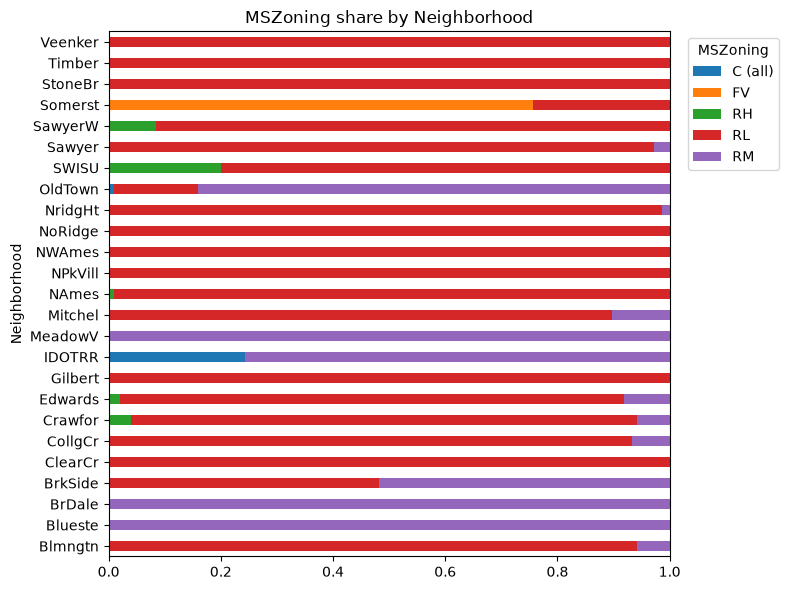

Most common zone in each neighbourhood: 91.6% correct
Most common zone overall: 78.8% correct


In [11]:
# Zone counts in train and test, including the NaNs.
print(pd.DataFrame({"Train": train["MSZoning"].value_counts(dropna=False), "Test": test["MSZoning"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# The test houses with a missing MSZoning.
missing_zoning = test[test["MSZoning"].isnull()]
display(missing_zoning[["Neighborhood", "MSSubClass", "LotArea", "BldgType", "YearBuilt"]])

# Share of each zone within each neighbourhood (train).
ax = pd.crosstab(train["Neighborhood"], train["MSZoning"], normalize="index").plot.barh(
    stacked=True, figsize=(8, 6), title="MSZoning share by Neighborhood"
)
ax.legend(title="MSZoning", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# How well does the most common zone in each neighbourhood predict the zone (in-sample)?
counts = pd.crosstab(train["Neighborhood"], train["MSZoning"])
print(f"Most common zone in each neighbourhood: {counts.max(axis=1).sum() / counts.values.sum():.1%} correct")
print(f"Most common zone overall: {(train['MSZoning'] == train['MSZoning'].mode()[0]).mean():.1%} correct")

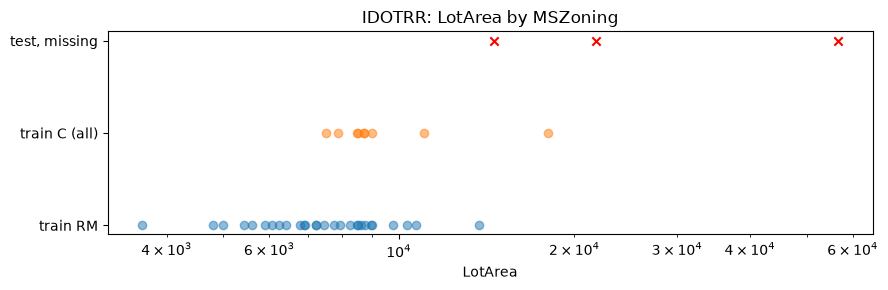

Largest LotArea in IDOTRR (train): {'C (all)': 18000, 'RM': 13710}
Train houses with LotArea > 14000, by zone: {'RL': 161, 'RM': 3, 'C (all)': 1}


In [12]:
# IDOTRR holds three of the four missing houses. Compare their lot areas with the train houses there.
idotrr = train[train["Neighborhood"] == "IDOTRR"]

fig, ax = plt.subplots(figsize=(9, 3))
for y, zone in enumerate(["RM", "C (all)"]):
    areas = idotrr.loc[idotrr["MSZoning"] == zone, "LotArea"]
    ax.scatter(areas, [y] * len(areas), alpha=0.5)
unknown = missing_zoning.loc[missing_zoning["Neighborhood"] == "IDOTRR", "LotArea"]
ax.scatter(unknown, [2] * len(unknown), marker="x", color="red")
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["train RM", "train C (all)", "test, missing"])
ax.set_xscale("log")
ax.set_xlabel("LotArea")
ax.set_title("IDOTRR: LotArea by MSZoning")
plt.tight_layout()
plt.show()

print("Largest LotArea in IDOTRR (train):", idotrr.groupby("MSZoning")["LotArea"].max().to_dict())
print("Train houses with LotArea > 14000, by zone:", train.loc[train["LotArea"] > 14000, "MSZoning"].value_counts().to_dict())

##### Findings:
- `MSZoning` has no NaNs in train. Test has 4 (0.3%), so this is a small problem.
- The zones are dominated by `RL` (79% of train houses), followed by `RM` (15%), with `FV`, `RH` and `C (all)` making up the rest.
- Zone depends strongly on neighbourhood. Most neighbourhoods are dominated by one zone, although 14 of 25 contain more than one. The most common zone in each neighbourhood is right for 91.6% of train houses (in-sample), against 78.8% for always using the overall most common zone (`RL`).
- One missing test house is in `Mitchel`, which is 90% `RL` in train (44 of 49).
- Three missing test houses are in `IDOTRR`, which is mixed in train (76% `RM` and 24% `C (all)`).
- The three `IDOTRR` lots (14,584, 21,780 and 56,600 sq ft) are all larger than any `RM` lot in `IDOTRR` (maximum 13,710). The only `IDOTRR` lot of that size in train is `C (all)` (18,000 sq ft). Across train, lots above 14,000 sq ft are almost all `RL` (161 of 165), then `RM` (3) and `C (all)` (1). Lot size therefore hints that these three houses may be `C (all)`, but this rests on a single house.

##### Decision:
Fill each missing `MSZoning` with the most common zone in the same `Neighborhood` in train (a conditional mode), implemented in `src/features.py`.

Methodology:
- For each neighbourhood, find the most common zone in train.
- Fill each missing house with the zone for its neighbourhood (`RL` for `Mitchel` and `RM` for `IDOTRR`).
- Fall back to the overall most common zone (`RL`) for a neighbourhood that is not in train. This does not happen here.
- Use train only, so no test information is used.

Reasons:
- Neighbourhood is the strongest simple predictor (91.6% against 78.8%) and is never missing.
- Only 4 of 1,459 test houses are affected, so a more complex model is not justified.
- The three `IDOTRR` fills are uncertain, because the neighbourhood is mixed and lot size points the other way. We keep the simple rule, as the lot size evidence rests on one house, but this is the first place to look if `MSZoning` turns out to matter.

In [13]:
from src.features import fill_ms_zoning

# Fill from the train zones. Train has no NaNs in MSZoning, so only test changes.
train_filled = fill_ms_zoning(train_filled, train)
test_filled = fill_ms_zoning(test_filled, train)

display(test_filled.loc[missing_zoning.index, ["Neighborhood", "MSZoning"]])
print("NaNs remaining in MSZoning (train, test):", train_filled["MSZoning"].isnull().sum(), test_filled["MSZoning"].isnull().sum())

,Neighborhood,MSZoning
Id,,
1916,IDOTRR,RM
2217,IDOTRR,RM
2251,IDOTRR,RM
2905,Mitchel,RL


NaNs remaining in MSZoning (train, test): 0 0


#### Utilities
`Utilities` describes the utilities available to the property (`AllPub` for all public utilities, down to `ELO` for electricity only). We ask:
- How much is missing, in train and in test?
- How much does the column vary?
- Is it worth keeping, and if so how should the missing houses be filled?

In [14]:
# Values in train and test, including the NaNs.
print(pd.DataFrame({"Train": train["Utilities"].value_counts(dropna=False), "Test": test["Utilities"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# The one train house that is not AllPub, against the median sale price in its neighbourhood.
odd = train[train["Utilities"] != "AllPub"]
display(odd[["Utilities", "Neighborhood", "LotArea", "YearBuilt", "OverallQual", "SalePrice"]])
print("Median SalePrice in", odd["Neighborhood"].iloc[0], ":", train.loc[train["Neighborhood"] == odd["Neighborhood"].iloc[0], "SalePrice"].median(), "\n")

# The test houses with a missing Utilities, and the values in their neighbourhoods in train.
missing_utilities = test[test["Utilities"].isnull()]
display(missing_utilities[["Neighborhood", "LotArea", "YearBuilt", "OverallQual", "Street"]])
for nb in missing_utilities["Neighborhood"].unique():
    print(nb, train.loc[train["Neighborhood"] == nb, "Utilities"].value_counts().to_dict())

           Train  Test
Utilities             
AllPub      1457  1457
NoSeWa         1     0
NaN            0     2 



,Utilities,Neighborhood,LotArea,YearBuilt,OverallQual,SalePrice
Id,,,,,,
945,NoSeWa,Timber,14375,1958,6,137500


Median SalePrice in Timber : 228475.0 



,Neighborhood,LotArea,YearBuilt,OverallQual,Street
Id,,,,,
1916,IDOTRR,21780,1910,2,Grvl
1946,Gilbert,31220,1952,6,Pave


IDOTRR {'AllPub': 37}
Gilbert {'AllPub': 79}


##### Findings:
- `Utilities` has almost no variation. Train has 1,457 `AllPub` houses and 1 `NoSeWa` house (Id 945), and every known test house is `AllPub`.
- Test has 2 NaNs (Ids 1916 and 1946), in `IDOTRR` and `Gilbert`. Every train house in both neighbourhoods is `AllPub` (37 and 79 houses).
- The single `NoSeWa` house (in `Timber`) sold for 137,500, against a neighbourhood median of 228,475. A model could memorise this one house, which would not generalise, and no test house has that value to apply it to.

##### Decision:
Drop `Utilities` from train and test, implemented in `src/features.py`.

Reasons:
- A column that is the same for 99.9% of houses carries no information for prediction.
- The one different train house would only add noise, and no test house shares its value.
- Dropping the column also removes the 2 test NaNs, so no fill is needed. Filling them with `AllPub` would give the same values as the other houses in their neighbourhoods, but there is no reason to keep the column.

In [15]:
from src.features import drop_utilities

train_filled = drop_utilities(train_filled)
test_filled = drop_utilities(test_filled)
print("Utilities still present (train, test):", "Utilities" in train_filled.columns, "Utilities" in test_filled.columns)

Utilities still present (train, test): False False


#### Exterior1st and Exterior2nd
`Exterior1st` is the main covering on the outside of the house, and `Exterior2nd` is a second material when there is more than one. We ask:
- How much is missing, in train and in test?
- How do the two columns relate?
- What predicts the material, and can it be used for the missing house?

Train: {'Exterior1st': 0, 'Exterior2nd': 0} , Test: {'Exterior1st': 1, 'Exterior2nd': 1} 



,Exterior1st,Exterior2nd,Neighborhood,YearBuilt,YearRemodAdd,HouseStyle,ExterQual
Id,,,,,,,
2152,NaN,NaN,Edwards,1940,2007,1Story,TA


Exterior2nd equals Exterior1st: 85.3%
After matching the spellings: 90.6%



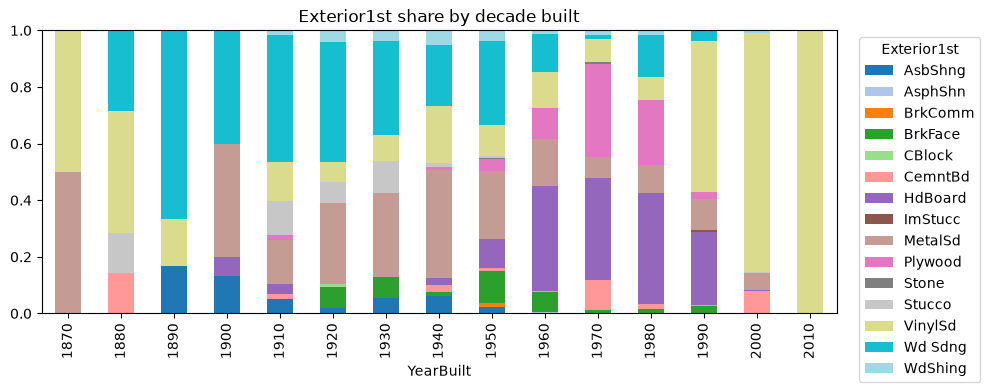

Neighborhood: 47.3%
Decade: 51.0%
Neighborhood + Decade: 56.2%
MSSubClass: 43.1%
HouseStyle: 39.0%
Most common overall: 35.3%

Built in the same decade: {'MetalSd': 30, 'Wd Sdng': 17, 'VinylSd': 16, 'AsbShng': 5}
Same decade and neighbourhood: {'MetalSd': 8, 'VinylSd': 5, 'Wd Sdng': 3, 'WdShing': 2}
remodelled since 2000: 17% VinylSd (n=102)
never remodelled: 11% VinylSd (n=102)


In [16]:
# Missing values in train and test.
exterior = ["Exterior1st", "Exterior2nd"]
print("Train:", train[exterior].isnull().sum().to_dict(), ", Test:", test[exterior].isnull().sum().to_dict(), "\n")

# The test house with a missing Exterior1st and Exterior2nd.
missing_exterior = test[test["Exterior1st"].isnull() | test["Exterior2nd"].isnull()]
display(missing_exterior[exterior + ["Neighborhood", "YearBuilt", "YearRemodAdd", "HouseStyle", "ExterQual"]])

# How often do the two columns agree? Three materials are spelled differently in each column.
spelling = {"CmentBd": "CemntBd", "Wd Shng": "WdShing", "Brk Cmn": "BrkComm"}
print(f"Exterior2nd equals Exterior1st: {(train['Exterior1st'] == train['Exterior2nd']).mean():.1%}")
print(f"After matching the spellings: {(train['Exterior1st'] == train['Exterior2nd'].replace(spelling)).mean():.1%}\n")

# Exterior1st by decade built (train).
decade = (train["YearBuilt"] // 10) * 10
ax = pd.crosstab(decade, train["Exterior1st"], normalize="index").plot.bar(
    stacked=True, figsize=(10, 4), colormap="tab20", title="Exterior1st share by decade built"
)
ax.legend(title="Exterior1st", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# How well does the most common material in each group predict Exterior1st? Leave-one-out, so a house never predicts itself.
def loo_mode_accuracy(df, keys, target):
    overall = df[target].mode()[0]
    correct = 0
    for _, group in df.groupby(keys)[target]:
        counts = group.value_counts()
        for label, n in counts.items():
            rest = counts.copy()
            rest[label] -= 1
            rest = rest[rest > 0]
            predicted = rest.idxmax() if len(rest) else overall
            correct += n * (predicted == label)
    return correct / len(df)


frame = train.assign(Decade=decade)
for keys in (["Neighborhood"], ["Decade"], ["Neighborhood", "Decade"], ["MSSubClass"], ["HouseStyle"]):
    print(f"{' + '.join(keys)}: {loo_mode_accuracy(frame, keys, 'Exterior1st'):.1%}")
print(f"Most common overall: {(train['Exterior1st'] == train['Exterior1st'].mode()[0]).mean():.1%}\n")

# What does train say for houses like the missing one?
house = missing_exterior.iloc[0]
same_decade = train[decade == (house["YearBuilt"] // 10) * 10]
print("Built in the same decade:", same_decade["Exterior1st"].value_counts().head(4).to_dict())
print("Same decade and neighbourhood:", same_decade.loc[same_decade["Neighborhood"] == house["Neighborhood"], "Exterior1st"].value_counts().head(4).to_dict())

# Does a remodel point to new siding? VinylSd share of houses built before 1960.
old = train[train["YearBuilt"] < 1960]
groups = {
    "remodelled since 2000": old[old["YearRemodAdd"] >= 2000],
    "never remodelled": old[old["YearRemodAdd"] == old["YearBuilt"]],
}
for label, group in groups.items():
    print(f"{label}: {(group['Exterior1st'] == 'VinylSd').mean():.0%} VinylSd (n={len(group)})")

##### Findings:
- Train has no NaNs in either column. Test has one house (Id 2152) that is missing both. It is a one-storey house in `Edwards`, built in 1940 and remodelled in 2007.
- The two columns usually agree, as `Exterior2nd` repeats `Exterior1st` when there is only one material. They match for 85.3% of train houses, and for 90.6% once three differently spelled materials are matched (`CemntBd` and `CmentBd`, `WdShing` and `Wd Shng`, `BrkComm` and `Brk Cmn`).
- The material changes with the era. `Wd Sdng` is the most common material for houses built up to the 1950s (except the 1940s, where it is `MetalSd`), `HdBoard` for the 1960s to 1980s, and `VinylSd` from the 1990s (53% of 1990s houses and 84% of 2000s houses).
- Decade built is the best single predictor of `Exterior1st`. Using the most common material in each group is right for 51.0% of houses by decade (leave-one-out), against 47.3% by neighbourhood, 43.1% by `MSSubClass`, 39.0% by `HouseStyle` and 35.3% overall (`VinylSd`). Neighbourhood and decade together reach 56.2%, but many of those groups are small.
- For Id 2152, `MetalSd` is the most common material among the 79 train houses built in the 1940s (30 houses, ahead of 17 for `Wd Sdng` and 16 for `VinylSd`). It is also the most common among the 18 in `Edwards` (8 houses, ahead of 5 for `VinylSd`). Both rules give the same answer.
- A remodel does not point to new siding. For houses built before 1960, 17% of those remodelled since 2000 have `VinylSd`, against 11% of those never remodelled.

##### Decision:
Fill `Exterior1st` with the most common material in train for houses built in the same decade, and `Exterior2nd` with the filled `Exterior1st`, implemented in `src/features.py`.

Methodology:
- For each decade built, find the most common `Exterior1st` in train.
- Fill each missing `Exterior1st` with the material for its decade (`MetalSd` for Id 2152).
- Fill each missing `Exterior2nd` with the filled `Exterior1st`, using the `Exterior2nd` spelling of the three materials that differ.
- Fall back to the overall most common material (`VinylSd`) for a decade that is not in train.
- Use train only, so no test information is used.

Reasons:
- Decade built is the strongest simple predictor and is never missing. Adding neighbourhood scores slightly higher, but gives the same material for this house, so the simpler rule is kept.
- Copying `Exterior1st` into `Exterior2nd` matches 90.6% of train houses, which is far better than any group rule for predicting a single material (35% to 56%).
- Only one test house is affected, so a more complex model is not justified.
- The spelling difference between the two columns needs handling if they are ever combined, for example when encoding them as shared categories.

In [17]:
from src.features import fill_exterior

# Fill from the train materials. Train has no NaNs in these columns, so only test changes.
train_filled = fill_exterior(train_filled, train)
test_filled = fill_exterior(test_filled, train)

display(test_filled.loc[missing_exterior.index, ["Exterior1st", "Exterior2nd", "Neighborhood", "YearBuilt"]])
exterior = ["Exterior1st", "Exterior2nd"]
print("NaNs remaining (train, test):", train_filled[exterior].isnull().sum().sum(), test_filled[exterior].isnull().sum().sum())

,Exterior1st,Exterior2nd,Neighborhood,YearBuilt
Id,,,,
2152,MetalSd,MetalSd,Edwards,1940


NaNs remaining (train, test): 0 0


#### KitchenQual
`KitchenQual` is the quality of the kitchen, from `Ex` (excellent) to `Po` (poor). We ask:
- How much is missing, in train and in test?
- How does it relate to the other quality ratings?
- What predicts the rating, and can it be used for the missing house?

             Train  Test
KitchenQual             
Ex              98   105
Fa              39    31
Gd             586   565
TA             735   757
NaN              0     1 



,Neighborhood,OverallQual,ExterQual,BsmtQual,YearBuilt,YearRemodAdd
Id,,,,,,
1556,ClearCr,5,TA,Gd,1917,1950


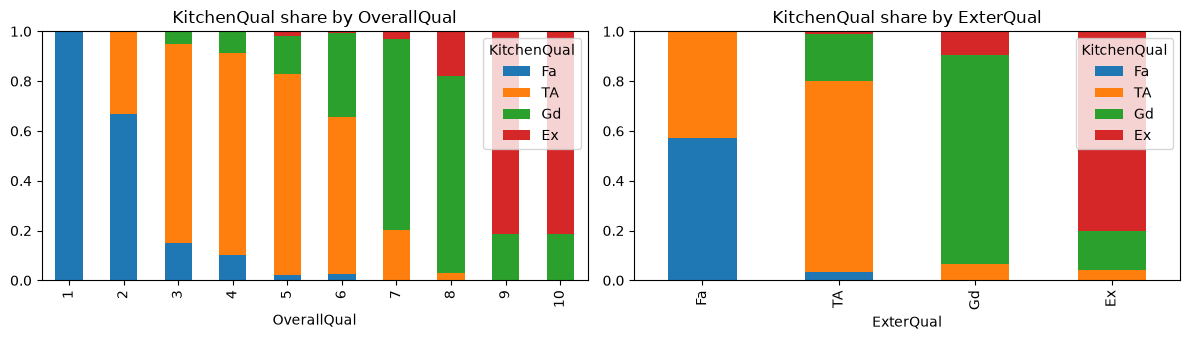

OverallQual: 75.0%
ExterQual: 78.9%
Neighborhood: 69.8%
OverallQual + ExterQual: 79.8%
Most common overall: 50.4%

Same OverallQual: {'TA': 320, 'Gd': 60, 'Fa': 9, 'Ex': 8}
Same OverallQual and ExterQual: {'TA': 309, 'Gd': 53, 'Fa': 8, 'Ex': 8}
Same neighbourhood: {'TA': 14, 'Gd': 12, 'Ex': 2}


In [18]:
# Values in train and test, including the NaNs.
print(pd.DataFrame({"Train": train["KitchenQual"].value_counts(dropna=False), "Test": test["KitchenQual"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# The test house with a missing KitchenQual, alongside its other quality ratings.
missing_kitchen = test[test["KitchenQual"].isnull()]
display(missing_kitchen[["Neighborhood", "OverallQual", "ExterQual", "BsmtQual", "YearBuilt", "YearRemodAdd"]])

# Kitchen quality against overall and exterior quality (train, share of each row).
order = ["Fa", "TA", "Gd", "Ex"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
pd.crosstab(train["OverallQual"], train["KitchenQual"], normalize="index")[order].plot.bar(
    stacked=True, ax=axes[0], title="KitchenQual share by OverallQual"
)
pd.crosstab(train["ExterQual"], train["KitchenQual"], normalize="index").loc[order, order].plot.bar(
    stacked=True, ax=axes[1], title="KitchenQual share by ExterQual"
)
plt.tight_layout()
plt.show()

# How well does the most common KitchenQual in each group predict it? Uses loo_mode_accuracy from the Exterior section.
for keys in (["OverallQual"], ["ExterQual"], ["Neighborhood"], ["OverallQual", "ExterQual"]):
    print(f"{' + '.join(keys)}: {loo_mode_accuracy(train, keys, 'KitchenQual'):.1%}")
print(f"Most common overall: {(train['KitchenQual'] == train['KitchenQual'].mode()[0]).mean():.1%}\n")

# What does train say for houses like the missing one?
house = missing_kitchen.iloc[0]
same_quality = train[(train["OverallQual"] == house["OverallQual"]) & (train["ExterQual"] == house["ExterQual"])]
print("Same OverallQual:", train.loc[train["OverallQual"] == house["OverallQual"], "KitchenQual"].value_counts().to_dict())
print("Same OverallQual and ExterQual:", same_quality["KitchenQual"].value_counts().to_dict())
print("Same neighbourhood:", train.loc[train["Neighborhood"] == house["Neighborhood"], "KitchenQual"].value_counts().to_dict())

##### Findings:
- Train has no NaNs in `KitchenQual`. Test has one house (Id 1556), in `ClearCr`, with `OverallQual` 5 and `ExterQual` `TA`, built in 1917 and remodelled in 1950.
- The ratings are `Ex`, `Gd`, `TA` and `Fa` (no house is rated `Po`). `TA` is the most common, at 50.4% of train houses.
- Kitchen quality follows the other quality ratings. Houses with a higher `OverallQual` or `ExterQual` are rated `Gd` or `Ex` more often.
- The most common `KitchenQual` in each group is right for 79.8% of train houses when grouped by `OverallQual` and `ExterQual` together (leave-one-out). Using `ExterQual` alone gives 78.9%, `OverallQual` alone 75.0% and neighbourhood 69.8%, against 50.4% for always using `TA`.
- For Id 1556, 320 of the 397 train houses with `OverallQual` 5 (81%) are rated `TA`, and so are 309 of the 378 that also have `ExterQual` `TA` (82%). Its neighbourhood is less clear, with `TA` (14 houses) and `Gd` (12) close together. Every rule that uses the quality ratings gives `TA`.

##### Decision:
Fill `KitchenQual` with the most common rating in train for houses with the same `OverallQual` and `ExterQual`, implemented in `src/features.py`.

Methodology:
- For each combination of `OverallQual` and `ExterQual`, find the most common `KitchenQual` in train.
- Fill each missing house with the rating for its combination (`TA` for Id 1556).
- Fall back to the most common rating for the same `OverallQual`, then to the most common overall (`TA`), for a combination that is not in train.
- Use train only, so no test information is used.

Reasons:
- The combination of the two quality ratings predicts best (79.8%), and neither rating is ever missing.
- Neighbourhood is weaker (69.8%) and gives a close call for this house.
- Only one test house is affected, so a more complex model is not justified.

In [19]:
from src.features import fill_kitchen_qual

# Fill from the train ratings. Train has no NaNs in KitchenQual, so only test changes.
train_filled = fill_kitchen_qual(train_filled, train)
test_filled = fill_kitchen_qual(test_filled, train)

display(test_filled.loc[missing_kitchen.index, ["KitchenQual", "OverallQual", "ExterQual", "Neighborhood"]])
print("NaNs remaining in KitchenQual (train, test):", train_filled["KitchenQual"].isnull().sum(), test_filled["KitchenQual"].isnull().sum())

,KitchenQual,OverallQual,ExterQual,Neighborhood
Id,,,,
1556,TA,5,TA,ClearCr


NaNs remaining in KitchenQual (train, test): 0 0


#### Functional
`Functional` is the home functionality, from `Typ` (typical) through increasing deductions to `Sal` (salvage only). The data description says to assume typical unless deductions are warranted. We ask:
- How much is missing, in train and in test?
- How is it distributed, and does it relate to the condition of the house?
- Can anything predict a deduction better than assuming `Typ`?

            Train  Test
Functional             
Maj1           14     5
Maj2            5     4
Min1           31    34
Min2           34    36
Mod            15    20
Sev             1     1
Typ          1358  1357
NaN             0     2 



,Neighborhood,OverallQual,OverallCond,YearBuilt,ExterQual,KitchenQual,SaleCondition
Id,,,,,,,
2217,IDOTRR,1,5,1952,Fa,Fa,Abnorml
2474,IDOTRR,4,1,1910,Fa,TA,Abnorml


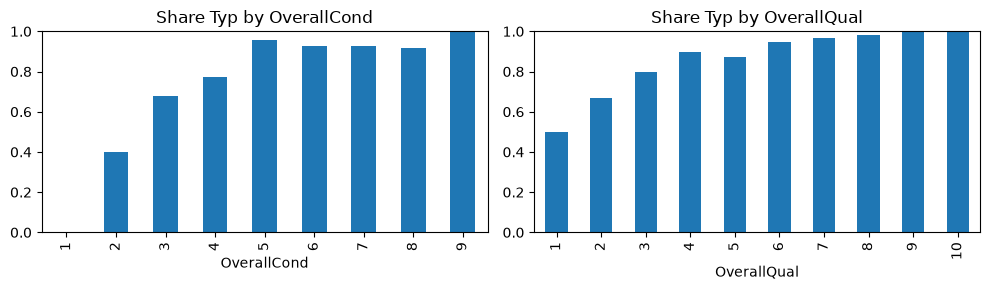

Functional,Typ,Min1,Min2,Mod,Maj1,Maj2,Sev
OverallCond,,,,,,,
1,0,0,0,0,1,0,0
2,2,0,1,1,0,1,0
3,17,1,1,3,2,1,0
4,44,3,6,1,2,1,0
5,783,13,10,4,7,1,1
6,234,8,6,2,1,1,0
7,190,4,7,4,0,0,0
8,66,2,3,0,1,0,0
9,22,0,0,0,0,0,0


OverallCond: 93.1%
Neighborhood: 93.1%
Always Typ: 93.1%

OverallCond 1 or 2: {'Typ': 2, 'Mod': 1, 'Maj1': 1, 'Maj2': 1, 'Min2': 1}
IDOTRR: {'Typ': 35, 'Maj2': 1, 'Mod': 1}


In [20]:
# Values in train and test, including the NaNs.
print(pd.DataFrame({"Train": train["Functional"].value_counts(dropna=False), "Test": test["Functional"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# The test houses with a missing Functional.
missing_functional = test[test["Functional"].isnull()]
display(missing_functional[["Neighborhood", "OverallQual", "OverallCond", "YearBuilt", "ExterQual", "KitchenQual", "SaleCondition"]])

# Share of houses with typical functionality, by overall condition and by overall quality (train).
typical = train["Functional"] == "Typ"
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
typical.groupby(train["OverallCond"]).mean().plot.bar(ax=axes[0], title="Share Typ by OverallCond", ylim=(0, 1))
typical.groupby(train["OverallQual"]).mean().plot.bar(ax=axes[1], title="Share Typ by OverallQual", ylim=(0, 1))
plt.tight_layout()
plt.show()

# How many houses are behind each bar? Counts of each Functional value by overall condition.
order = ["Typ", "Min1", "Min2", "Mod", "Maj1", "Maj2", "Sev"]
display(pd.crosstab(train["OverallCond"], train["Functional"]).reindex(columns=order, fill_value=0))

# Does the most common Functional in a group beat always using Typ? Uses loo_mode_accuracy from the Exterior section.
for keys in (["OverallCond"], ["Neighborhood"]):
    print(f"{' + '.join(keys)}: {loo_mode_accuracy(train, keys, 'Functional'):.1%}")
print(f"Always Typ: {typical.mean():.1%}\n")

# Functional for the worst conditions, and in the neighbourhood of the missing houses.
print("OverallCond 1 or 2:", train.loc[train["OverallCond"] <= 2, "Functional"].value_counts().to_dict())
print("IDOTRR:", train.loc[train["Neighborhood"] == "IDOTRR", "Functional"].value_counts().to_dict())

##### Findings:
- Train has no NaNs in `Functional`. Test has two houses (Ids 2217 and 2474), both in `IDOTRR`, both sold under abnormal conditions and both in poor shape. Id 2217 has `OverallQual` 1 and Id 2474 has `OverallCond` 1.
- `Typ` is by far the most common value (93.1% of train houses). The rest are deductions: `Min2` (34), `Min1` (31), `Mod` (15), `Maj1` (14), `Maj2` (5) and `Sev` (1). The data description says to assume typical functionality unless deductions are warranted.
- The share of `Typ` falls as condition gets worse: 96% at `OverallCond` 5, 77% at 4, 68% at 3 and 2 of 6 houses at 1 or 2. It falls with `OverallQual` in the same way.
- Even so, grouping the houses does no better than always predicting `Typ`. The most common value in each group of `OverallCond` or neighbourhood is right for 93.1% of houses (leave-one-out), the same as always using `Typ`.
- In the worst group (`OverallCond` 1 or 2, only 6 houses), `Typ` is still the most common single value (2 houses), and the four deductions seen have one house each. No particular deduction is a better guess than `Typ`.
- `IDOTRR` is mostly `Typ` in train (35 of 37 houses).

##### Decision:
Fill missing `Functional` with `Typ`, implemented in `src/features.py`.

Reasons:
- The data description says to assume `Typ` unless deductions are warranted.
- `Typ` is the most common value in every group large enough to measure, and no alternative beats it.
- Both houses are in poor condition, so they may well have deductions, but nothing in train points to which one. Picking a deduction would be a guess among several levels that are each rarer than `Typ`.
- Only two test houses are affected, so a more complex model is not justified.

In [21]:
from src.features import fill_functional

# Train has no NaNs in Functional, so only test changes.
train_filled = fill_functional(train_filled)
test_filled = fill_functional(test_filled)

display(test_filled.loc[missing_functional.index, ["Functional", "Neighborhood", "OverallQual", "OverallCond"]])
print("NaNs remaining in Functional (train, test):", train_filled["Functional"].isnull().sum(), test_filled["Functional"].isnull().sum())

,Functional,Neighborhood,OverallQual,OverallCond
Id,,,,
2217,Typ,IDOTRR,1,5
2474,Typ,IDOTRR,4,1


NaNs remaining in Functional (train, test): 0 0


#### Electrical
`Electrical` is the electrical system, from `SBrkr` (standard circuit breakers) to the older fuse boxes (`FuseA`, `FuseF`, `FuseP`) and `Mix`. We ask:
- How much is missing, in train and in test?
- How is it distributed, and what does it depend on?
- Can anything predict the system better than assuming `SBrkr`?

            Train  Test
Electrical             
FuseA          94    94
FuseF          27    23
FuseP           3     5
Mix             1     0
SBrkr        1332  1337
NaN             1     0 



,Neighborhood,YearBuilt,YearRemodAdd,Heating,CentralAir,OverallQual,SaleCondition
Id,,,,,,,
1380,Timber,2006,2007,GasA,Y,5,Normal


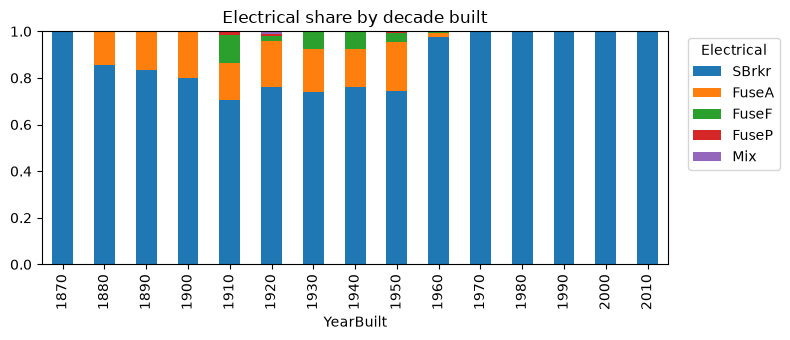

YearBuilt,1870,1880,1890,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010
Electrical,,,,,,,,,,,,,,,
SBrkr,2,6,5,12,41,74,40,60,124,171,188,61,163,384,1
FuseA,0,1,1,3,9,19,10,13,35,3,0,0,0,0,0
FuseF,0,0,0,0,7,2,4,6,7,1,0,0,0,0,0
FuseP,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0
Mix,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


Decade: 91.4%
Neighborhood: 91.4%
Always SBrkr: 91.4%

Built in the same decade: {'SBrkr': 384}
Built in the same year: {'SBrkr': 66}
Same neighbourhood: {'SBrkr': 36, 'FuseA': 1}


In [22]:
# Values in train and test, including the NaNs.
print(pd.DataFrame({"Train": train["Electrical"].value_counts(dropna=False), "Test": test["Electrical"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# The train house with a missing Electrical.
missing_electrical = train[train["Electrical"].isnull()]
display(missing_electrical[["Neighborhood", "YearBuilt", "YearRemodAdd", "Heating", "CentralAir", "OverallQual", "SaleCondition"]])

# Share of each system by decade built (train), and the number of houses behind each bar.
order = ["SBrkr", "FuseA", "FuseF", "FuseP", "Mix"]
decade = (train["YearBuilt"] // 10) * 10
ax = pd.crosstab(decade, train["Electrical"], normalize="index")[order].plot.bar(
    stacked=True, figsize=(8, 3.5), title="Electrical share by decade built"
)
ax.legend(title="Electrical", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(pd.crosstab(decade, train["Electrical"])[order].T)

# Does the most common Electrical in a group beat always using SBrkr? Uses loo_mode_accuracy from the Exterior section.
known = train.dropna(subset=["Electrical"]).assign(Decade=decade)
for keys in (["Decade"], ["Neighborhood"]):
    print(f"{' + '.join(keys)}: {loo_mode_accuracy(known, keys, 'Electrical'):.1%}")
print(f"Always SBrkr: {(known['Electrical'] == 'SBrkr').mean():.1%}\n")

# What does train say for houses like the missing one?
house = missing_electrical.iloc[0]
print("Built in the same decade:", train.loc[decade == (house["YearBuilt"] // 10) * 10, "Electrical"].value_counts().to_dict())
print("Built in the same year:", train.loc[train["YearBuilt"] == house["YearBuilt"], "Electrical"].value_counts().to_dict())
print("Same neighbourhood:", train.loc[train["Neighborhood"] == house["Neighborhood"], "Electrical"].value_counts().to_dict())

##### Findings:
- Test has no NaNs in `Electrical`. Train has one house (Id 1380), in `Timber`, built in 2006 and remodelled in 2007, with central air.
- `SBrkr` (standard circuit breakers) is the most common system, at 91.4% of the houses with a known value. The rest are `FuseA` (94), `FuseF` (27), `FuseP` (3) and `Mix` (1).
- The system depends on the age of the house. Houses built before 1960 are mostly `SBrkr` but often not (71% to 86% by decade, apart from the 1870s, which has only 2 houses). From 1960 onwards almost every house is `SBrkr` (98% in the 1960s and 100% in every decade after).
- Grouping the houses does no better than always predicting `SBrkr`. The most common system in each decade or neighbourhood is right for 91.4% of houses (leave-one-out), the same as always using `SBrkr`, as it is the most common value in every group.
- For Id 1380, all 384 other train houses built in the 2000s are `SBrkr`, including all 66 built in 2006. The other `Timber` houses are almost all `SBrkr` too (36 of 37).

##### Decision:
Fill missing `Electrical` with the most common system in train for houses built in the same decade (`SBrkr` for Id 1380), implemented in `src/features.py`.

Methodology:
- For each decade built, find the most common `Electrical` in train.
- Fill each missing house with the system for its decade.
- Fall back to the overall most common system (`SBrkr`) for a decade that is not in train.
- Use train only, so no test information is used.

Reasons:
- Age is the clearest driver of the electrical system, and every house built since 1960 is almost certainly `SBrkr`, so the fill for a house built in 2006 is very safe.
- Nothing else about the house is unusual, so there is no reason to drop the row.
- Only one house is affected, so a more complex model is not justified.

In [23]:
from src.features import fill_electrical

# Test has no NaNs in Electrical, so only train changes.
train_filled = fill_electrical(train_filled, train)
test_filled = fill_electrical(test_filled, train)

display(train_filled.loc[missing_electrical.index, ["Electrical", "Neighborhood", "YearBuilt"]])
print("NaNs remaining in Electrical (train, test):", train_filled["Electrical"].isnull().sum(), test_filled["Electrical"].isnull().sum())

,Electrical,Neighborhood,YearBuilt
Id,,,
1380,SBrkr,Timber,2006


NaNs remaining in Electrical (train, test): 0 0


#### SaleType
`SaleType` is the type of sale, such as `WD` (conventional warranty deed), `New` (a newly built house) or `COD` (court officer deed or estate). We ask:
- How much is missing, in train and in test?
- How is it distributed, and what does it depend on?
- What predicts the type, and can it be used for the missing house?

          Train  Test
SaleType             
COD          43    44
CWD           4     8
Con           2     3
ConLD         9    17
ConLI         5     4
ConLw         5     3
New         120   117
Oth           3     4
WD         1267  1258
NaN           0     1 



,Neighborhood,SaleCondition,YearBuilt,YrSold,MSSubClass,OverallQual
Id,,,,,,
2490,Sawyer,Normal,1958,2007,20,5


SaleType,WD,New,COD,ConLD,ConLI,ConLw,CWD,Oth,Con
SaleCondition,,,,,,,,,
Abnorml,70,0,24,2,1,0,1,3,0
AdjLand,4,0,0,0,0,0,0,0,0
Alloca,12,0,0,0,0,0,0,0,0
Family,19,0,0,0,0,0,1,0,0
Normal,1160,0,19,6,4,5,2,0,2
Partial,2,120,0,1,0,0,0,0,0


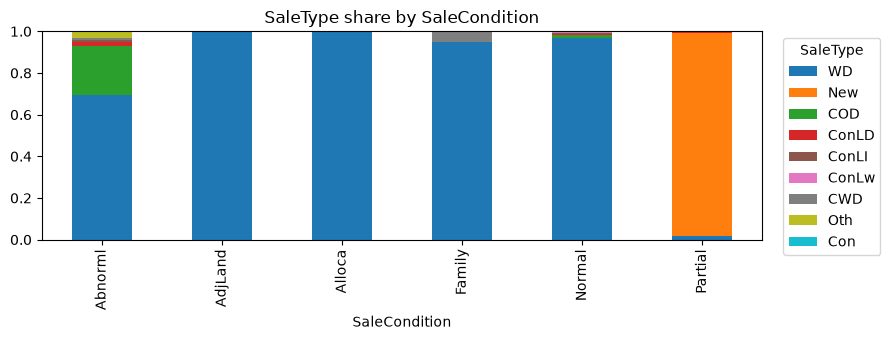

SaleCondition: 95.0%
Neighborhood: 86.8%
YrSold: 86.9%
Always WD: 86.9%

Same SaleCondition: {'WD': 1160, 'COD': 19, 'ConLD': 6, 'ConLw': 5, 'ConLI': 4, 'CWD': 2, 'Con': 2}
Same SaleCondition, sold more than a year after being built: {'WD': 1121, 'COD': 19, 'ConLD': 6, 'ConLw': 5, 'ConLI': 3, 'CWD': 2, 'Con': 1}


In [24]:
# Values in train and test, including the NaNs.
print(pd.DataFrame({"Train": train["SaleType"].value_counts(dropna=False), "Test": test["SaleType"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# The test house with a missing SaleType.
missing_sale = test[test["SaleType"].isnull()]
display(missing_sale[["Neighborhood", "SaleCondition", "YearBuilt", "YrSold", "MSSubClass", "OverallQual"]])

# SaleType against SaleCondition (train): counts, and the share of each condition.
order = train["SaleType"].value_counts().index
counts = pd.crosstab(train["SaleCondition"], train["SaleType"])[order]
display(counts)
ax = counts.div(counts.sum(axis=1), axis=0).plot.bar(
    stacked=True, figsize=(9, 3.5), colormap="tab10", title="SaleType share by SaleCondition"
)
ax.legend(title="SaleType", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Does the most common SaleType in a group beat always using WD? Uses loo_mode_accuracy from the Exterior section.
for keys in (["SaleCondition"], ["Neighborhood"], ["YrSold"]):
    print(f"{' + '.join(keys)}: {loo_mode_accuracy(train, keys, 'SaleType'):.1%}")
print(f"Always WD: {(train['SaleType'] == 'WD').mean():.1%}\n")

# What does train say for sales like the missing one?
house = missing_sale.iloc[0]
same_condition = train[train["SaleCondition"] == house["SaleCondition"]]
older = same_condition[same_condition["YrSold"] - same_condition["YearBuilt"] > 1]
print("Same SaleCondition:", same_condition["SaleType"].value_counts().to_dict())
print("Same SaleCondition, sold more than a year after being built:", older["SaleType"].value_counts().to_dict())

##### Findings:
- Train has no NaNs in `SaleType`. Test has one house (Id 2490), in `Sawyer`, sold in 2007 under a `Normal` sale condition. It was built in 1958, so it was 49 years old at the time of sale.
- `WD` (conventional warranty deed) is the most common type, at 86.9% of train houses. The rest are `New` (120), `COD` (43), `ConLD` (9), `ConLI` (5), `ConLw` (5), `CWD` (4), `Oth` (3) and `Con` (2).
- `SaleType` depends strongly on `SaleCondition`. Every `New` sale is a `Partial` sale (120 of the 123 `Partial` sales are `New`), and a `Normal` sale is `WD` for 97% of houses (1,160 of 1,198). `Abnorml` sales are less often `WD` (69%) and include most of the `COD` sales.
- Using the most common type for each `SaleCondition` is right for 95.0% of train houses (leave-one-out), against 86.9% for always using `WD`. Neighbourhood and year sold give no improvement (86.8% and 86.9%).
- For Id 2490, `New` is ruled out, as it is not a `Partial` sale and the house is old. Among the 1,198 `Normal` sales in train, `WD` is by far the most common, and no other type exceeds 19 houses (`COD`).

##### Decision:
Fill missing `SaleType` with the most common type in train for the same `SaleCondition` (`WD` for Id 2490), implemented in `src/features.py`.

Methodology:
- For each `SaleCondition`, find the most common `SaleType` in train.
- Fill each missing house with the type for its condition.
- Fall back to the overall most common type (`WD`) for a condition that is not in train.
- Use train only, so no test information is used.

Reasons:
- `SaleCondition` is the strongest predictor, never missing, and takes the accuracy from 86.9% to 95.0%.
- For a `Normal` sale, `WD` is overwhelmingly the most likely type.
- Only one test house is affected, so a more complex model is not justified.

In [25]:
from src.features import fill_sale_type

# Train has no NaNs in SaleType, so only test changes.
train_filled = fill_sale_type(train_filled, train)
test_filled = fill_sale_type(test_filled, train)

display(test_filled.loc[missing_sale.index, ["SaleType", "SaleCondition", "Neighborhood"]])
print("NaNs remaining in SaleType (train, test):", train_filled["SaleType"].isnull().sum(), test_filled["SaleType"].isnull().sum())

,SaleType,SaleCondition,Neighborhood
Id,,,
2490,WD,Normal,Sawyer


NaNs remaining in SaleType (train, test): 0 0


#### MasVnrType and MasVnrArea
`MasVnrType` is the type of masonry veneer on the outside of the house (`None`, `BrkFace`, `Stone` or `BrkCmn`), and `MasVnrArea` is its area in square feet. `None` is a real type that means no veneer, so `src/data.py` reads only `NA` as a missing value (explained in the findings). We ask:
- How much is missing, in train and in test?
- How do the two columns relate?
- What predicts the veneer type, and can it be used for the missing houses?

            Train  Test
MasVnrType             
BrkCmn         15    10
BrkFace       445   434
None          864   878
Stone         126   121
NaN             8    16 



,Data,MasVnrType,MasVnrArea,Neighborhood,YearBuilt,ExterQual,SaleCondition
Id,,,,,,,
235,train,NaN,NaN,Gilbert,2002,Gd,Normal
530,train,NaN,NaN,Crawfor,1957,Gd,Alloca
651,train,NaN,NaN,Somerst,2007,Gd,Normal
937,train,NaN,NaN,SawyerW,2003,Gd,Normal
974,train,NaN,NaN,Somerst,2007,Gd,Partial
978,train,NaN,NaN,Somerst,2006,Gd,Partial
1244,train,NaN,NaN,NridgHt,2006,Ex,Partial
1279,train,NaN,NaN,CollgCr,2002,Gd,Normal
1692,test,NaN,NaN,Gilbert,2002,Gd,Normal


Built in 2002 or later: 22 of 24



MasVnrArea,0,>0,NaN
MasVnrType,,,
BrkCmn,0,15,0
BrkFace,1,444,0
NaN,0,0,8
None,859,5,0
Stone,1,125,0


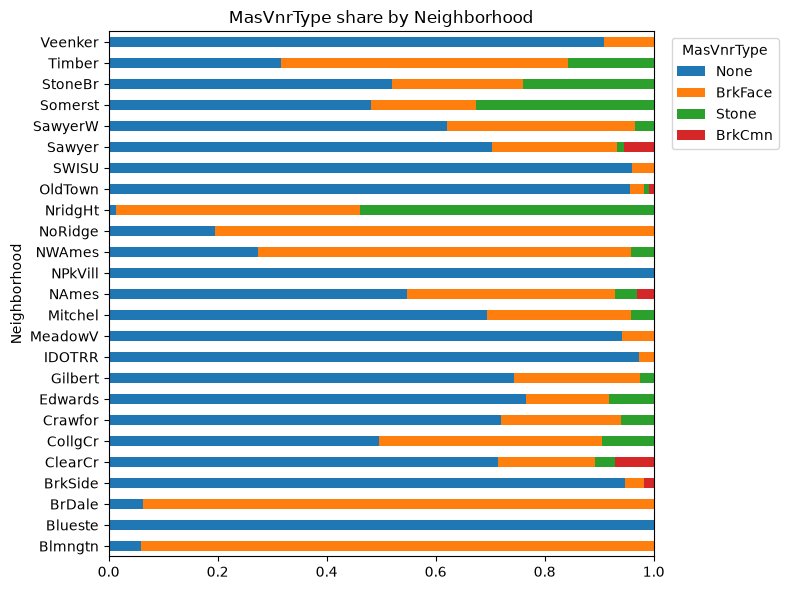

Neighborhood: 68.7%
Decade: 59.7%
ExterQual: 60.9%
OverallQual: 62.1%
Always None: 59.6%

Built 2002 to 2008 with ExterQual Gd (258 houses): {'None': 93, 'BrkFace': 89, 'Stone': 76}
Type when there is a veneer: {'BrkFace': 444, 'Stone': 125, 'BrkCmn': 15}
Median area by type: {'BrkCmn': 192.0, 'BrkFace': 202.5, 'Stone': 205.0}


In [26]:
# Missing values in train and test.
veneer = ["MasVnrType", "MasVnrArea"]
print(pd.DataFrame({"Train": train["MasVnrType"].value_counts(dropna=False), "Test": test["MasVnrType"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# The genuinely missing houses. They are mostly recent.
missing_train = train[train[veneer].isnull().any(axis=1)]
missing_test = test[test[veneer].isnull().any(axis=1)]
missing_veneer = pd.concat([missing_train.assign(Data="train"), missing_test.assign(Data="test")])
display(missing_veneer[["Data"] + veneer + ["Neighborhood", "YearBuilt", "ExterQual", "SaleCondition"]])
print(f"Built in 2002 or later: {(missing_veneer['YearBuilt'] >= 2002).sum()} of {len(missing_veneer)}\n")

# How do the two columns relate? A type of None should go with an area of 0.
area_state = np.where(train["MasVnrArea"].isnull(), "NaN", np.where(train["MasVnrArea"] == 0, "0", ">0"))
display(pd.crosstab(train["MasVnrType"].fillna("NaN"), area_state, rownames=["MasVnrType"], colnames=["MasVnrArea"]))

# Veneer type by neighbourhood (train).
known = train.dropna(subset=["MasVnrType"])
order = ["None", "BrkFace", "Stone", "BrkCmn"]
ax = pd.crosstab(known["Neighborhood"], known["MasVnrType"], normalize="index")[order].plot.barh(
    stacked=True, figsize=(8, 6), title="MasVnrType share by Neighborhood"
)
ax.legend(title="MasVnrType", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Does the most common type in a group beat always using None? Uses loo_mode_accuracy from the Exterior section.
frame = known.assign(Decade=(known["YearBuilt"] // 10) * 10)
for keys in (["Neighborhood"], ["Decade"], ["ExterQual"], ["OverallQual"]):
    print(f"{' + '.join(keys)}: {loo_mode_accuracy(frame, keys, 'MasVnrType'):.1%}")
print(f"Always None: {(known['MasVnrType'] == 'None').mean():.1%}\n")

# Houses like the recent missing ones: built 2002 to 2008 with a good exterior.
similar = known[known["YearBuilt"].between(2002, 2008) & (known["ExterQual"] == "Gd")]
print(f"Built 2002 to 2008 with ExterQual Gd ({len(similar)} houses):", similar["MasVnrType"].value_counts().to_dict())

# When there is a veneer, which type is it, and how large? Used for Id 2611 and for the fill of the area.
veneers = known[(known["MasVnrType"] != "None") & (known["MasVnrArea"] > 0)]
print("Type when there is a veneer:", veneers["MasVnrType"].value_counts().to_dict())
print("Median area by type:", veneers.groupby("MasVnrType")["MasVnrArea"].median().to_dict())

##### Findings:
- The file marks a missing value as `NA`, but `None` is a real veneer type (no veneer). Pandas reads both as NaN by default, which made 872 train and 894 test houses look missing, when only 8 and 16 are.
- The loaders in `src/data.py` now pass `keep_default_na=False` and `na_values=["NA"]`, so that only `NA` is read as NaN. `MasVnrType` is the only column that contains the string `None`, and the files have no empty strings, so no other column is affected.
- This leaves 8 genuinely missing houses in train (864 are `None`) and 16 in test (878 are `None`). The counts below rely on these settings, so data loaded without them, or in a kernel started before the change, shows the old counts.
- The 8 train houses are missing both columns. In test, 15 houses are missing both, and Id 2611 is missing only the type, with an area of 198 sq ft.
- The two columns agree: a type of `None` has an area of 0 for 859 of the 864 train houses. The exceptions are small inconsistencies in the source data (5 `None` houses with an area, and one `BrkFace` and one `Stone` house with an area of 0).
- The missing houses are mostly recent. 22 of the 24 were built in 2002 or later, and nearly all have an exterior quality of `Gd`. They are therefore not a random sample.
- A veneer is common among similar houses. Of the 258 train houses built from 2002 to 2008 with `ExterQual` `Gd`, only 36% have no veneer (`None` 93, `BrkFace` 89 and `Stone` 76).
- Neighbourhood is the only predictor that clearly helps. The most common type in each neighbourhood is right for 68.7% of houses (leave-one-out), against 62.1% for `OverallQual`, 60.9% for `ExterQual`, 59.7% for decade built and 59.6% for always using `None`.
- When there is a veneer, it is `BrkFace` for 76% of houses (444 of 584), and the median area is 192 sq ft for `BrkCmn`, 202.5 for `BrkFace` and 205 for `Stone`.

##### Decision:
Fill `MasVnrType` and `MasVnrArea` from the same rule and add a `MasVnrMissing` flag, implemented in `src/features.py`.

Methodology:
- Load the data with only `NA` as missing, as `src/data.py` now does, so that `None` stays a category.
- Fill each missing `MasVnrType` with the most common type in the same `Neighborhood` in train. This gives `None` for most houses, `Stone` in `NridgHt` and `BrkFace` in `Timber`.
- If the area is known and above 0 (Id 2611), there is a veneer, so use the most common veneer type instead (`BrkFace`).
- Fill each missing `MasVnrArea` with 0 if the type is `None`, otherwise with the median area of that type in train.
- Add a `MasVnrMissing` flag, since the missing houses are mostly recent and may differ from the rest.
- Use train only, so no test information is used.

Reasons:
- Neighbourhood is the only predictor that beats always using `None`, and it is never missing.
- A veneer type with an area of 0 would contradict the data, so the area follows the type.
- Reading `None` as NaN would make the most common type in train look like `BrkFace` (445 houses), so the fill depends on the loader keeping `None` as a category.
- The `None` fill for the recent houses is uncertain, as similar houses have a veneer about two times in three. `None` is still the most common type in their neighbourhoods (`Gilbert`, `Somerst` and `CollgCr`), though not by a wide margin in `Somerst`. The flag lets a model learn whether these houses behave differently.

In [27]:
from src.features import fill_masonry

train_filled = fill_masonry(train_filled, train)
test_filled = fill_masonry(test_filled, train)

filled = pd.concat([train_filled.loc[missing_train.index], test_filled.loc[missing_test.index]])
display(filled[["MasVnrType", "MasVnrArea", "Neighborhood", "YearBuilt"]])
print("NaNs remaining (train, test):", train_filled[veneer].isnull().sum().sum(), test_filled[veneer].isnull().sum().sum())

,MasVnrType,MasVnrArea,Neighborhood,YearBuilt
Id,,,,
235,None,0.0,Gilbert,2002
530,None,0.0,Crawfor,1957
651,None,0.0,Somerst,2007
937,None,0.0,SawyerW,2003
974,None,0.0,Somerst,2007
978,None,0.0,Somerst,2006
1244,Stone,205.0,NridgHt,2006
1279,None,0.0,CollgCr,2002
1692,None,0.0,Gilbert,2002


NaNs remaining (train, test): 0 0


#### Alley
`Alley` is the type of alley access to the property: `Grvl` (gravel), `Pave` (paved) or `NA` (no alley access). We ask:
- How much is missing, in train and in test?
- Does a NaN really mean no alley access?
- Is the column informative enough to keep?

       Train  Test
Alley             
NaN     1367  1352
Grvl      50    70
Pave      41    37 

Share with alley access: train 6.2%, test 7.3%



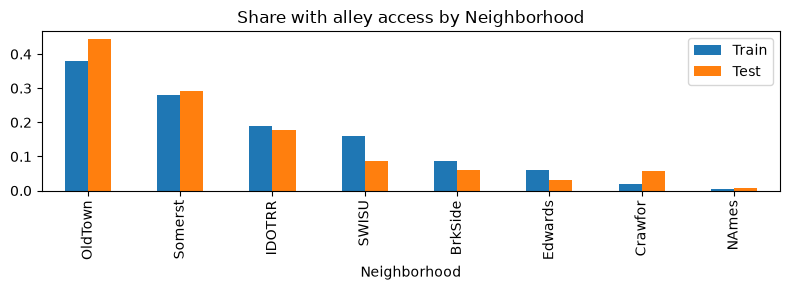

Train: 8 neighbourhoods with alley access, 13.1% of their houses have it
Test: 8 neighbourhoods with alley access, 15.0% of their houses have it


Alley,Grvl,None,Pave
MSZoning,,,
C (all),0,8,2
FV,0,41,24
RH,0,14,2
RL,14,1129,6
RM,36,175,7


,Houses,All houses,Alley neighbourhoods
Alley,,,
Grvl,50,119500.0,119500.0
None,1367,165000.0,139000.0
Pave,41,172500.0,172500.0


In [28]:
# Values in train and test, including the NaNs. A NaN means no alley access.
print(pd.DataFrame({"Train": train["Alley"].value_counts(dropna=False), "Test": test["Alley"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")
print(f"Share with alley access: train {train['Alley'].notnull().mean():.1%}, test {test['Alley'].notnull().mean():.1%}\n")

# Share of houses with alley access by neighbourhood, in train and in test (neighbourhoods with any alley only).
has_alley = pd.DataFrame(
    {
        "Train": train["Alley"].notnull().groupby(train["Neighborhood"]).mean(),
        "Test": test["Alley"].notnull().groupby(test["Neighborhood"]).mean(),
    }
).fillna(0)
alley_areas = has_alley[(has_alley > 0).any(axis=1)].sort_values("Train", ascending=False)
alley_areas.plot.bar(figsize=(8, 3), title="Share with alley access by Neighborhood")
plt.tight_layout()
plt.show()

# Is the share the same in train and test, within the neighbourhoods that have alleys?
for label, df in [("Train", train), ("Test", test)]:
    in_areas = df[df["Neighborhood"].isin(alley_areas.index)]
    print(f"{label}: {len(alley_areas)} neighbourhoods with alley access, {in_areas['Alley'].notnull().mean():.1%} of their houses have it")

# Alley type by zone (train).
display(pd.crosstab(train["MSZoning"], train["Alley"].fillna("None")))

# Does alley access matter for the sale price? Median SalePrice, overall and within the neighbourhoods that have alleys.
in_alley_areas = train[train["Neighborhood"].isin(alley_areas.index)]
display(
    pd.DataFrame(
        {
            "Houses": train["Alley"].fillna("None").value_counts(),
            "All houses": train.groupby(train["Alley"].fillna("None"))["SalePrice"].median(),
            "Alley neighbourhoods": in_alley_areas.groupby(in_alley_areas["Alley"].fillna("None"))["SalePrice"].median(),
        }
    )
)

##### Findings:
- A NaN in `Alley` means no alley access, as the data description says, so it is not a missing value. 93.8% of train houses and 92.7% of test houses have no alley access. The rest have gravel (`Grvl`, 50 in train and 70 in test) or paved (`Pave`, 41 and 37) access.
- Alley access is concentrated in a few neighbourhoods. 8 of the 25 train neighbourhoods have any, mainly `OldTown` (43 of 113 houses), `Somerst` (24 of 86) and `IDOTRR` (7 of 37). Test has the same 8 neighbourhoods, and the share with access within them is similar (13.1% in train and 15.0% in test), so there is no sign that the NaNs hide genuinely missing values.
- The type of alley goes with the zone. Gravel alleys are mostly in `RM` zones (36 of 50) and paved alleys mostly in `FV` zones (24 of 41).
- Alley access carries information about price. Median sale prices are 119,500 for `Grvl`, 172,500 for `Pave` and 165,000 for no alley. Within the neighbourhoods that have alleys, the medians are 119,500, 172,500 and 139,000.

##### Decision:
Fill the NaNs in `Alley` with `None`, so that no alley access becomes its own category, implemented in `src/features.py`.

Reasons:
- The data description defines a NaN as no alley access, and nothing in train or test suggests otherwise.
- Having no alley is informative, as it sits between gravel and paved in the neighbourhoods that have alleys, so it is better kept as a category than dropped.
- The fill uses no statistics from the data, so there is nothing to compute from train.
- The same function, `fill_absent`, will be used for the other columns where a NaN means the feature is absent.

In [29]:
from src.features import fill_absent

train_filled = fill_absent(train_filled, ["Alley"])
test_filled = fill_absent(test_filled, ["Alley"])

print("Train:", train_filled["Alley"].value_counts().to_dict())
print("Test:", test_filled["Alley"].value_counts().to_dict())

Train: {'None': 1367, 'Grvl': 50, 'Pave': 41}
Test: {'None': 1352, 'Grvl': 70, 'Pave': 37}


#### FireplaceQu
`FireplaceQu` is the quality of the fireplace, from `Ex` (excellent) to `Po` (poor), with `NA` meaning no fireplace. We ask:
- How much is missing, in train and in test?
- Does a NaN really mean no fireplace?
- Is the column informative enough to keep?

             Train  Test
FireplaceQu             
Ex              24    19
Fa              33    41
Gd             378   364
Po              20    26
TA             313   279
NaN            690   730 

Share with a fireplace: train 52.7%, test 50.0%

Train


FireplaceQu is NaN,False,True
Fireplaces,,
0,0,690
1,649,0
2,115,0
3,4,0


Test


FireplaceQu is NaN,False,True
Fireplaces,,
0,0,730
1,618,0
2,104,0
3,6,0
4,1,0


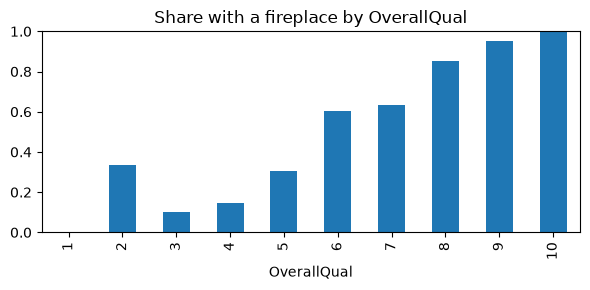

,Houses,Median SalePrice
FireplaceQu,,
None,690,135000.0
Po,20,131500.0
Fa,33,158000.0
TA,313,187500.0
Gd,378,207000.0
Ex,24,314250.0


In [30]:
# Values in train and test, including the NaNs. A NaN means no fireplace.
print(pd.DataFrame({"Train": train["FireplaceQu"].value_counts(dropna=False), "Test": test["FireplaceQu"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")
print(f"Share with a fireplace: train {train['FireplaceQu'].notnull().mean():.1%}, test {test['FireplaceQu'].notnull().mean():.1%}\n")

# Does a NaN line up with the number of fireplaces being 0?
for label, df in [("Train", train), ("Test", test)]:
    print(label)
    display(pd.crosstab(df["Fireplaces"], df["FireplaceQu"].isnull(), rownames=["Fireplaces"], colnames=["FireplaceQu is NaN"]))

# Share of houses with a fireplace by overall quality (train).
train["FireplaceQu"].notnull().groupby(train["OverallQual"]).mean().plot.bar(
    figsize=(6, 3), title="Share with a fireplace by OverallQual", ylim=(0, 1)
)
plt.tight_layout()
plt.show()

# Does the fireplace rating matter for the sale price? Number of houses and median SalePrice by rating.
order = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
rating = train["FireplaceQu"].fillna("None")
display(pd.DataFrame({"Houses": rating.value_counts(), "Median SalePrice": train.groupby(rating)["SalePrice"].median()}).loc[order])

##### Findings:
- A NaN in `FireplaceQu` means no fireplace, as the data description says. In both train (690 houses) and test (730), the NaNs are exactly the houses with `Fireplaces` equal to 0, and every house with at least one fireplace has a rating. No value is genuinely missing.
- About half of the houses have no fireplace (47.3% in train and 50.0% in test). The ratings in train are `Gd` (378), `TA` (313), `Fa` (33), `Ex` (24) and `Po` (20).
- Fireplaces are more common in better houses. The share with one rises from 30% at `OverallQual` 5 to 60% at 6, 85% at 8 and 95% at 9.
- The rating goes with price. Median sale prices rise from 131,500 for `Po` to 158,000 for `Fa`, 187,500 for `TA`, 207,000 for `Gd` and 314,250 for `Ex`. Houses with no fireplace have a median of 135,000, close to `Po`.

##### Decision:
Fill the NaNs in `FireplaceQu` with `None`, so that no fireplace becomes its own category, using `fill_absent` in `src/features.py`.

Reasons:
- The data description defines a NaN as no fireplace, and the NaNs match `Fireplaces == 0` exactly in both datasets.
- No fireplace is informative, as it sits at the bottom of the price scale, so it is better kept as a category than dropped. When the quality ratings are encoded later, `None` can be the lowest level of the same scale.
- The fill uses no statistics from the data, so there is nothing to compute from train.

In [31]:
from src.features import fill_absent

train_filled = fill_absent(train_filled, ["FireplaceQu"])
test_filled = fill_absent(test_filled, ["FireplaceQu"])

print("Train:", train_filled["FireplaceQu"].value_counts().to_dict())
print("Test:", test_filled["FireplaceQu"].value_counts().to_dict())

Train: {'None': 690, 'Gd': 378, 'TA': 313, 'Fa': 33, 'Ex': 24, 'Po': 20}
Test: {'None': 730, 'Gd': 364, 'TA': 279, 'Fa': 41, 'Po': 26, 'Ex': 19}


#### PoolQC
`PoolQC` is the quality of the pool, from `Ex` (excellent) to `Fa` (fair), with `NA` meaning no pool. We ask:
- How much is missing, in train and in test?
- Does a NaN really mean no pool?
- Are there houses with a pool but no rating, and how can they be filled?

        Train  Test
PoolQC             
Ex          2     2
Fa          2     0
Gd          2     1
NaN      1452  1456 

Train


PoolQC is NaN,False,True
PoolArea > 0,,
False,0,1452
True,6,0


Test


PoolQC is NaN,False,True
PoolArea > 0,,
False,0,1453
True,3,3


,Data,PoolArea,PoolQC,OverallQual,ExterQual,YearBuilt,Neighborhood
Id,,,,,,,
198,train,512,Ex,8,Gd,1918,NAmes
811,train,648,Fa,6,TA,1974,NWAmes
1171,train,576,Gd,6,TA,1977,Mitchel
1183,train,555,Ex,10,Gd,1996,NoRidge
1387,train,519,Fa,7,TA,1978,NWAmes
1424,train,738,Gd,6,Gd,1966,Edwards
1975,test,144,Ex,10,Ex,2003,NridgHt
2421,test,368,NaN,4,TA,1953,NAmes
2504,test,444,NaN,6,TA,1984,SawyerW


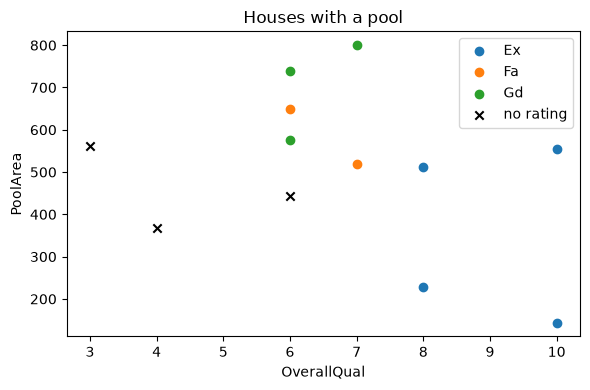

Train pool ratings: {'Ex': 2, 'Fa': 2, 'Gd': 2}
Train pool ratings, houses with ExterQual TA: {'Fa': 2, 'Gd': 1} 



,Houses,Median SalePrice
PoolArea,,
False,1452,162900.0
True,6,242500.0


In [32]:
# Values in train and test, including the NaNs. A NaN should mean no pool.
print(pd.DataFrame({"Train": train["PoolQC"].value_counts(dropna=False), "Test": test["PoolQC"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# Does a NaN line up with the pool area being 0?
for label, df in [("Train", train), ("Test", test)]:
    print(label)
    display(pd.crosstab(df["PoolArea"] > 0, df["PoolQC"].isnull(), rownames=["PoolArea > 0"], colnames=["PoolQC is NaN"]))

# Every house with a pool, in train and test.
pools = pd.concat([train[train["PoolArea"] > 0].assign(Data="train"), test[test["PoolArea"] > 0].assign(Data="test")])
display(pools[["Data", "PoolArea", "PoolQC", "OverallQual", "ExterQual", "YearBuilt", "Neighborhood"]])

# Pool rating against overall quality and pool area, with the unrated houses marked.
colours = {"Fa": "tab:orange", "Gd": "tab:green", "Ex": "tab:blue"}
fig, ax = plt.subplots(figsize=(6, 4))
for rating, group in pools.dropna(subset=["PoolQC"]).groupby("PoolQC"):
    ax.scatter(group["OverallQual"], group["PoolArea"], label=rating, color=colours[rating])
unrated = pools[pools["PoolQC"].isnull()]
ax.scatter(unrated["OverallQual"], unrated["PoolArea"], marker="x", color="black", label="no rating")
ax.set_xlabel("OverallQual")
ax.set_ylabel("PoolArea")
ax.set_title("Houses with a pool")
ax.legend()
plt.tight_layout()
plt.show()

# What do the train pools say about the rating, and does a pool matter for the sale price?
has_pool = train["PoolArea"] > 0
print("Train pool ratings:", train.loc[has_pool, "PoolQC"].value_counts().to_dict())
print("Train pool ratings, houses with ExterQual TA:", train.loc[has_pool & (train["ExterQual"] == "TA"), "PoolQC"].value_counts().to_dict(), "\n")
display(pd.DataFrame({"Houses": has_pool.value_counts(), "Median SalePrice": train.groupby(has_pool)["SalePrice"].median()}))

##### Findings:
- Almost no house has a pool: 6 of the 1,458 train houses and 6 of the 1,459 test houses. Everything else is a NaN, which means no pool, as the data description says.
- In train, the NaNs are exactly the houses with a pool area of 0, and all 6 pools have a rating (`Ex` 2, `Fa` 2 and `Gd` 2). Removing Id 1299, which had a `Gd` pool, left the three ratings tied.
- In test, 1,453 NaNs have a pool area of 0, but 3 houses (Ids 2421, 2504 and 2600) have a pool of 368, 444 and 561 sq ft and no rating. These are genuinely missing.
- The three unrated houses were built in 1953, 1984 and 1953, with `OverallQual` 4, 6 and 3 and `ExterQual` `TA`. That is at or below the lowest of the houses with a rated pool (`OverallQual` 6 to 10).
- The rating cannot be predicted reliably from the data. With only 6 train pools, there is no clear link to pool area or quality. Among the train pools with `ExterQual` `TA`, the ratings are `Fa` (2) and `Gd` (1).
- Houses with a pool sell for more (median 242,500 against 162,900), but this rests on 6 houses.

##### Decision:
Fill `PoolQC` with `None` for houses with no pool, and for the 3 houses with a pool and no rating with the most common rating among train pools with the same `ExterQual` (`Fa`), implemented in `src/features.py`.

Reasons:
- The data description defines a NaN as no pool, and it matches a pool area of 0 in train and for 1,453 test houses.
- A house with a pool cannot have no pool, so the 3 unrated houses need a rating. The three ratings are tied among the 6 train pools (2 each), so the overall most common rating is not a usable rule. All 3 houses have `ExterQual` `TA`, and among the train pools with that exterior quality `Fa` is the most common (2 of 3).
- These 3 fills are a guess based on 3 houses, and the choice affects only 3 houses.
- Only 6 train houses have a pool, so the rating cannot be learned reliably. When selecting features, `PoolQC` could be replaced by a simple has-pool flag.


In [33]:
from src.features import fill_pool_qc

train_filled = fill_pool_qc(train_filled, train)
test_filled = fill_pool_qc(test_filled, train)

display(test_filled.loc[test["PoolArea"] > 0, ["PoolArea", "PoolQC"]])
print("NaNs remaining in PoolQC (train, test):", train_filled["PoolQC"].isnull().sum(), test_filled["PoolQC"].isnull().sum())

,PoolArea,PoolQC
Id,,
1975,144,Ex
2421,368,Fa
2504,444,Fa
2574,228,Ex
2600,561,Fa
2711,800,Gd


NaNs remaining in PoolQC (train, test): 0 0


#### Fence
`Fence` is the quality of the fence: `GdPrv` (good privacy), `MnPrv` (minimum privacy), `GdWo` (good wood), `MnWw` (minimum wood or wire) or `NA` (no fence). We ask:
- How much is missing, in train and in test?
- Does a NaN really mean no fence?
- Is the column informative enough to keep?

       Train  Test
Fence             
NaN     1177  1169
MnPrv    157   172
GdPrv     59    59
GdWo      54    58
MnWw      11     1 

Share with a fence: train 19.3%, test 19.9%



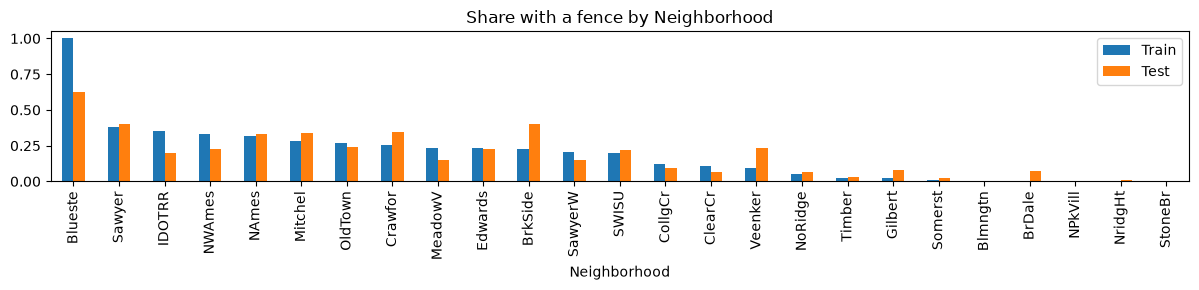

Correlation between the train and test shares: 0.88



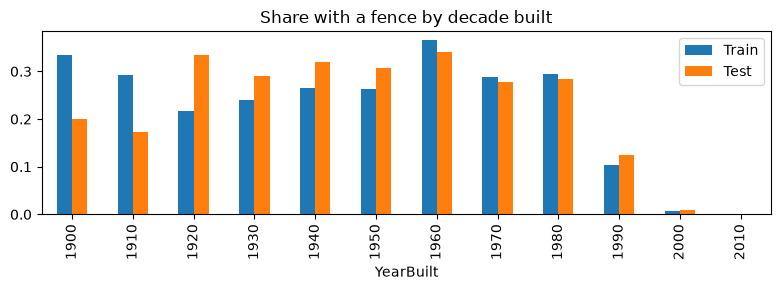

,Houses,Median SalePrice
Fence,,
None,1177,173000.0
GdPrv,59,167500.0
GdWo,54,138750.0
MnPrv,157,137450.0
MnWw,11,130000.0


Median price is lower with a fence in 7 of 19 neighbourhoods


In [34]:
# Values in train and test, including the NaNs. A NaN means no fence.
print(pd.DataFrame({"Train": train["Fence"].value_counts(dropna=False), "Test": test["Fence"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")
print(f"Share with a fence: train {train['Fence'].notnull().mean():.1%}, test {test['Fence'].notnull().mean():.1%}\n")

# Share of houses with a fence by neighbourhood, in train and in test.
share = pd.DataFrame(
    {
        "Train": train["Fence"].notnull().groupby(train["Neighborhood"]).mean(),
        "Test": test["Fence"].notnull().groupby(test["Neighborhood"]).mean(),
    }
).sort_values("Train", ascending=False)
share.plot.bar(figsize=(12, 3), title="Share with a fence by Neighborhood")
plt.tight_layout()
plt.show()
print(f"Correlation between the train and test shares: {share['Train'].corr(share['Test']):.2f}\n")

# Share of houses with a fence by decade built, in train and in test (1900 onwards).
decade_share = pd.DataFrame(
    {
        "Train": train["Fence"].notnull().groupby((train["YearBuilt"] // 10) * 10).mean(),
        "Test": test["Fence"].notnull().groupby((test["YearBuilt"] // 10) * 10).mean(),
    }
).loc[1900:]
decade_share.plot.bar(figsize=(8, 3), title="Share with a fence by decade built")
plt.tight_layout()
plt.show()

# Does the fence type matter for the sale price? Number of houses and median SalePrice by type.
fence_type = train["Fence"].fillna("None")
order = ["None", "GdPrv", "GdWo", "MnPrv", "MnWw"]
display(pd.DataFrame({"Houses": fence_type.value_counts(), "Median SalePrice": train.groupby(fence_type)["SalePrice"].median()}).loc[order])

# Is the gap just a neighbourhood effect? In how many neighbourhoods is the median price lower with a fence?
by_fence = train.groupby(["Neighborhood", train["Fence"].notnull()])["SalePrice"].median().unstack().dropna()
print(f"Median price is lower with a fence in {(by_fence[True] < by_fence[False]).sum()} of {len(by_fence)} neighbourhoods")

##### Findings:
- A NaN in `Fence` means no fence, as the data description says. 80.7% of train houses and 80.1% of test houses have no fence. The types in train are `MnPrv` (157), `GdPrv` (59), `GdWo` (54) and `MnWw` (11).
- Nothing suggests that some NaNs are genuinely missing. The share of houses with a fence in each neighbourhood is very similar in train and test (correlation 0.88), and so is the share by decade built.
- Fences are common in older neighbourhoods (`Sawyer` 38%, `IDOTRR` 35%, `NWAmes` 33% and `NAmes` 32%) and rare in newer ones (`Somerst` 1%, `Gilbert` 3% and `Timber` 3%, and none in `NridgHt` or `StoneBr`). Between 22% and 37% of houses built from 1900 to 1989 have a fence, against 10% of those built in the 1990s and 1% since 2000.
- Houses with no fence sell for the most (median 173,000), followed by `GdPrv` (167,500), `GdWo` (138,750), `MnPrv` (137,450) and `MnWw` (130,000). Part of the gap reflects age and neighbourhood, as fences are more common in older, cheaper areas, and the effect within a neighbourhood is not consistent (the median price is lower with a fence in only 7 of 19 neighbourhoods).
- The types are not a clear quality scale. `GdPrv` sells for far more than `GdWo` and `MnPrv`, so the order is not simply good to minimum.

##### Decision:
Fill the NaNs in `Fence` with `None`, so that no fence becomes its own category, using `fill_absent` in `src/features.py`.

Reasons:
- The data description defines a NaN as no fence, and train and test look the same on every check.
- No fence is informative, as it is the most common value and goes with newer, more expensive neighbourhoods, so it is better kept as a category than dropped.
- The types should be treated as separate categories rather than an ordered scale when encoding, as the privacy and wood types do not form a single order.
- The fill uses no statistics from the data, so there is nothing to compute from train.

In [35]:
from src.features import fill_absent

train_filled = fill_absent(train_filled, ["Fence"])
test_filled = fill_absent(test_filled, ["Fence"])

print("Train:", train_filled["Fence"].value_counts().to_dict())
print("Test:", test_filled["Fence"].value_counts().to_dict())

Train: {'None': 1177, 'MnPrv': 157, 'GdPrv': 59, 'GdWo': 54, 'MnWw': 11}
Test: {'None': 1169, 'MnPrv': 172, 'GdPrv': 59, 'GdWo': 58, 'MnWw': 1}


#### MiscFeature
`MiscFeature` is a miscellaneous feature not covered elsewhere: `Shed`, `Gar2` (a second garage), `Othr`, `TenC` (a tennis court), `Elev` (an elevator) or `NA` (none). `MiscVal` is its value in dollars. We ask:
- How much is missing, in train and in test?
- Does a NaN really mean no feature, and does it agree with `MiscVal`?
- Are there houses with a value but no feature type, and how can they be filled?

             Train  Test
MiscFeature             
Gar2             2     3
Othr             2     2
Shed            49    46
TenC             1     0
NaN           1404  1408 

Train


MiscFeature is NaN,False,True
MiscVal > 0,,
False,2,1404
True,52,0


Test


MiscFeature is NaN,False,True
MiscVal > 0,,
False,1,1407
True,50,1


,Data,MiscFeature,MiscVal,Neighborhood,YearBuilt,OverallQual,SaleCondition
Id,,,,,,,
874,train,Othr,0,NAmes,1949,5,Normal
1201,train,Shed,0,NAmes,1970,4,Abnorml
2432,test,Shed,0,NAmes,1959,5,Normal
2550,test,NaN,17000,Edwards,2008,10,Partial


,count,median,min,max
MiscFeature,,,,
Gar2,2,11900.0,8300,15500
Othr,1,3500.0,3500,3500
Shed,48,500.0,54,2500
TenC,1,2000.0,2000,2000


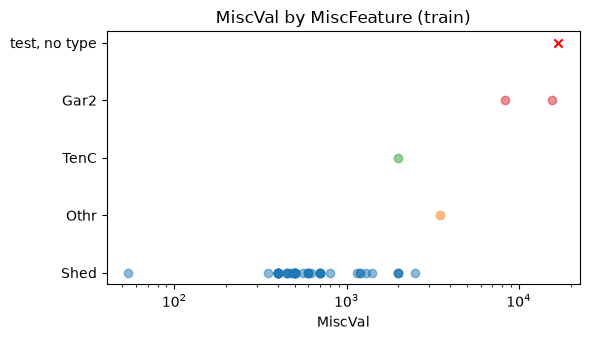

,Houses,Median SalePrice
MiscFeature,,
Gar2,2,170750.0
None,1404,164250.0
Othr,2,94000.0
Shed,49,144000.0
TenC,1,250000.0


In [36]:
# Values in train and test, including the NaNs. A NaN should mean no feature.
print(pd.DataFrame({"Train": train["MiscFeature"].value_counts(dropna=False), "Test": test["MiscFeature"].value_counts(dropna=False)}).fillna(0).astype(int), "\n")

# Does a NaN line up with MiscVal being 0?
for label, df in [("Train", train), ("Test", test)]:
    print(label)
    display(pd.crosstab(df["MiscVal"] > 0, df["MiscFeature"].isnull(), rownames=["MiscVal > 0"], colnames=["MiscFeature is NaN"]))

# The houses that break the pattern: a value with no type, and a type with no value.
columns = ["MiscFeature", "MiscVal", "Neighborhood", "YearBuilt", "OverallQual", "SaleCondition"]
breaks = pd.concat(
    [
        train[(train["MiscVal"] > 0) & train["MiscFeature"].isnull() | (train["MiscVal"] == 0) & train["MiscFeature"].notnull()].assign(Data="train"),
        test[(test["MiscVal"] > 0) & test["MiscFeature"].isnull() | (test["MiscVal"] == 0) & test["MiscFeature"].notnull()].assign(Data="test"),
    ]
)
display(breaks[["Data"] + columns])

# MiscVal by type in train, and the untyped test house marked (log scale).
display(train[train["MiscVal"] > 0].groupby("MiscFeature")["MiscVal"].agg(["count", "median", "min", "max"]))
types = ["Shed", "Othr", "TenC", "Gar2"]
untyped = test[test["MiscFeature"].isnull() & (test["MiscVal"] > 0)]
fig, ax = plt.subplots(figsize=(6, 3.5))
for y, kind in enumerate(types):
    values = train.loc[(train["MiscFeature"] == kind) & (train["MiscVal"] > 0), "MiscVal"]
    ax.scatter(values, [y] * len(values), alpha=0.5)
ax.scatter(untyped["MiscVal"], [len(types)] * len(untyped), marker="x", color="red")
ax.set_yticks(range(len(types) + 1))
ax.set_yticklabels(types + ["test, no type"])
ax.set_xscale("log")
ax.set_xlabel("MiscVal")
ax.set_title("MiscVal by MiscFeature (train)")
plt.tight_layout()
plt.show()

# Does the feature matter for the sale price? Number of houses and median SalePrice by type.
feature = train["MiscFeature"].fillna("None")
display(pd.DataFrame({"Houses": feature.value_counts(), "Median SalePrice": train.groupby(feature)["SalePrice"].median()}))

##### Findings:
- A NaN in `MiscFeature` means no feature, as the data description says. 96.3% of train houses (1,404) and 96.5% of test houses (1,408) have none. The types in train are `Shed` (49), `Gar2` (2), `Othr` (2) and `TenC` (1), and in test `Shed` (46), `Gar2` (3) and `Othr` (2). No house has an elevator (`Elev`).
- In train, `MiscVal` and the type agree. All 1,404 NaNs have a `MiscVal` of 0, and 52 of the 54 houses with a type have a value. Two houses (Ids 874 and 1201) have a type with a `MiscVal` of 0, and test has one (Id 2432). These are not missing values, so they are left as they are.
- In test, one house is genuinely missing a type. Id 2550 has a `MiscVal` of 17,000 but no `MiscFeature`. The other 1,407 NaNs have a `MiscVal` of 0.
- A value of 17,000 is larger than any in train. Sheds are small (median 500, maximum 2,500), `Othr` is 3,500 and `TenC` is 2,000. Only the second garages (`Gar2`) are in the thousands, at 8,300 and 15,500. `Gar2` is therefore the closest type.
- Houses with a shed sell for less (median 144,000 against 164,250 for none), though the other types have only 1 or 2 houses each.

##### Decision:
Fill `MiscFeature` with `None` where `MiscVal` is 0, and for Id 2550 with the type whose median `MiscVal` in train is closest to its value (`Gar2`), implemented in `src/features.py`.

Methodology:
- If `MiscFeature` is NaN and `MiscVal` is 0, fill with `None`.
- If `MiscFeature` is NaN and `MiscVal` is above 0, fill with the type whose median `MiscVal` in train is closest.
- Use train only, so no test information is used.

Reasons:
- The data description defines a NaN as no feature, and `MiscVal` agrees for every house but one.
- A house with a value must have a feature, and the value points to the type.
- The fill for Id 2550 is a guess based on one house, as `Othr` or an elevator (`Elev`, which does not appear in the data) are also possible. Only one house is affected.

In [37]:
from src.features import fill_misc_feature

train_filled = fill_misc_feature(train_filled, train)
test_filled = fill_misc_feature(test_filled, train)

display(test_filled.loc[untyped.index, ["MiscFeature", "MiscVal"]])
print("Train:", train_filled["MiscFeature"].value_counts().to_dict())
print("Test:", test_filled["MiscFeature"].value_counts().to_dict())

,MiscFeature,MiscVal
Id,,
2550,Gar2,17000


Train: {'None': 1404, 'Shed': 49, 'Gar2': 2, 'Othr': 2, 'TenC': 1}
Test: {'None': 1407, 'Shed': 46, 'Gar2': 4, 'Othr': 2}


#### Basement columns
The basement has 11 columns. Five are ratings: `BsmtQual` (height), `BsmtCond` (condition), `BsmtExposure` (walkout or garden level), `BsmtFinType1` and `BsmtFinType2` (finish types), where `NA` means no basement. Six are numbers: `BsmtFinSF1`, `BsmtFinSF2`, `BsmtUnfSF`, `TotalBsmtSF`, `BsmtFullBath` and `BsmtHalfBath`. We ask:
- How much is missing, in train and in test?
- Does a NaN in the ratings really mean no basement, and which houses break that pattern?
- What predicts each rating that is genuinely missing?

In [38]:
# Number of NaNs in each basement column, in train and in test.
categories = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
numbers = ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"]
display(pd.DataFrame({"Train": train[categories + numbers].isnull().sum(), "Test": test[categories + numbers].isnull().sum()}).T)

# With no basement, the five ratings should all be NaN together and TotalBsmtSF should be 0.
for label, df in [("Train", train), ("Test", test)]:
    n_nan = df[categories].isnull().sum(axis=1)
    all_nan = df[n_nan == 5]
    print(f"{label}: all five ratings NaN for {len(all_nan)} houses, some but not all for {((n_nan > 0) & (n_nan < 5)).sum()}")
    print(f"  of the {len(all_nan)} with all five NaN, TotalBsmtSF is 0 for {(all_nan['TotalBsmtSF'] == 0).sum()} and NaN for {all_nan['TotalBsmtSF'].isnull().sum()}")


# The houses that break the pattern: some ratings NaN but not all, or NaN in the numeric columns.
def irregular(df):
    n_nan = df[categories].isnull().sum(axis=1)
    return df[((n_nan > 0) & (n_nan < 5)) | df[numbers].isnull().any(axis=1)]


breaks = pd.concat([irregular(train).assign(Data="train"), irregular(test).assign(Data="test")])
display(breaks[["Data"] + categories + numbers + ["Foundation", "YearBuilt"]])

# Does the foundation say whether there is a basement? Houses and houses with no basement, by foundation (train).
no_basement = train[categories].isnull().all(axis=1)
display(pd.DataFrame({"Houses": train["Foundation"].value_counts(), "No basement": no_basement.groupby(train["Foundation"]).sum()}))

# The second finish type goes with the second finished area: BsmtFinType2 against BsmtFinSF2 > 0, for houses with a basement.
with_basement = train[~no_basement]
display(pd.crosstab(with_basement["BsmtFinSF2"] > 0, with_basement["BsmtFinType2"], rownames=["BsmtFinSF2 > 0"]))

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
Train,37,37,38,37,38,0,0,0,0,0,0
Test,44,45,44,42,42,1,1,1,1,2,2


Train: all five ratings NaN for 37 houses, some but not all for 2
  of the 37 with all five NaN, TotalBsmtSF is 0 for 37 and NaN for 0
Test: all five ratings NaN for 42 houses, some but not all for 7
  of the 42 with all five NaN, TotalBsmtSF is 0 for 41 and NaN for 1


,Data,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath,Foundation,YearBuilt
Id,,,,,,,,,,,,,,
333,train,Gd,TA,No,GLQ,NaN,1124.0,479.0,1603.0,3206.0,1.0,0.0,PConc,2003
949,train,Gd,TA,NaN,Unf,Unf,0.0,0.0,936.0,936.0,0.0,0.0,PConc,2002
1488,test,Gd,TA,NaN,Unf,Unf,0.0,0.0,1595.0,1595.0,0.0,0.0,PConc,2005
2041,test,Gd,NaN,Mn,GLQ,Rec,1044.0,382.0,0.0,1426.0,1.0,0.0,CBlock,1976
2121,test,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PConc,1946
2186,test,TA,NaN,No,BLQ,Unf,1033.0,0.0,94.0,1127.0,0.0,1.0,CBlock,1976
2189,test,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,Slab,1959
2218,test,NaN,Fa,No,Unf,Unf,0.0,0.0,173.0,173.0,0.0,0.0,Stone,1895
2219,test,NaN,TA,No,Unf,Unf,0.0,0.0,356.0,356.0,0.0,0.0,PConc,1910


,Houses,No basement
Foundation,,
BrkTil,146,1
CBlock,634,9
PConc,645,3
Slab,24,24
Stone,6,0
Wood,3,0


BsmtFinType2,ALQ,BLQ,GLQ,LwQ,Rec,Unf
BsmtFinSF2 > 0,,,,,,
False,0,0,0,0,0,1254
True,19,33,14,46,54,0


In [39]:
# What predicts each missing rating? Houses with a complete record of all five ratings.
# Uses loo_mode_accuracy from the Exterior section.
complete = train[train[categories].notnull().all(axis=1)].assign(Decade=lambda d: (d["YearBuilt"] // 10) * 10)
options = {
    "BsmtExposure": [["HouseStyle"], ["BsmtFinType1"]],
    "BsmtCond": [["BsmtQual"], ["ExterCond"]],
    "BsmtQual": [["Decade"], ["Foundation"], ["ExterQual"], ["BsmtCond"]],
}
for target, groupings in options.items():
    common = complete[target].mode()[0]
    print(f"{target}: always {common} is right for {(complete[target] == common).mean():.1%}")
    for keys in groupings:
        print(f"  {' + '.join(keys)}: {loo_mode_accuracy(complete, keys, target):.1%}")

# The values for houses like the ones with a missing rating.
unfinished = complete[(complete["BsmtFinType1"] == "Unf") & (complete["BsmtFinSF1"] == 0)]
print("\nBsmtExposure, fully unfinished basements:", unfinished["BsmtExposure"].value_counts().to_dict())
print("BsmtExposure, unfinished and built 2000 or later:", unfinished.loc[unfinished["YearBuilt"] >= 2000, "BsmtExposure"].value_counts().to_dict())
print("BsmtCond:", complete["BsmtCond"].value_counts().to_dict())
print("BsmtQual, built before 1920:", complete.loc[complete["YearBuilt"] < 1920, "BsmtQual"].value_counts().to_dict())
print("BsmtFinType2 when BsmtFinSF2 > 0:", complete.loc[complete["BsmtFinSF2"] > 0, "BsmtFinType2"].value_counts().to_dict())

BsmtExposure: always No is right for 67.1%
  HouseStyle: 69.8%
  BsmtFinType1: 67.1%
BsmtCond: always TA is right for 92.1%
  BsmtQual: 92.1%
  ExterCond: 92.1%
BsmtQual: always TA is right for 45.7%
  Decade: 78.2%
  Foundation: 72.7%
  ExterQual: 71.9%
  BsmtCond: 47.1%

BsmtExposure, fully unfinished basements: {'No': 345, 'Av': 46, 'Mn': 27, 'Gd': 11}
BsmtExposure, unfinished and built 2000 or later: {'No': 102, 'Av': 36, 'Gd': 11, 'Mn': 9}
BsmtCond: {'TA': 1307, 'Gd': 65, 'Fa': 45, 'Po': 2}
BsmtQual, built before 1920: {'TA': 64, 'Fa': 13, 'Gd': 10}
BsmtFinType2 when BsmtFinSF2 > 0: {'Rec': 54, 'LwQ': 46, 'BLQ': 33, 'ALQ': 19, 'GLQ': 14}


##### Findings:
- A NaN in the ratings means no basement. All 37 train houses with all five ratings NaN have a `TotalBsmtSF` of 0. In test it is 41 of the 42, and the other is Id 2121.
- Some houses break the pattern. In train, Id 333 has a second finished area (479 sq ft) but no `BsmtFinType2`, and Id 949 has an unfinished basement but no `BsmtExposure`. In test, 7 houses have one rating missing (`BsmtExposure` for Ids 1488 and 2349, `BsmtCond` for Ids 2041, 2186 and 2525, and `BsmtQual` for Ids 2218 and 2219), Id 2189 has NaN bathroom counts, and Id 2121 has everything NaN.
- Id 2189 has a slab foundation and every size is 0, so it has no basement. Its bathroom counts are simply not recorded, so they should be 0.
- Id 2121 is the hard case. Its five ratings and six numbers are all NaN, where the other houses with no basement have sizes of 0. Its foundation is poured concrete (`PConc`), and only 3 of the 645 `PConc` houses in train have no basement, so a basement may exist. Nothing else is known about it, so it is treated as having none.
- `BsmtFinType2` follows `BsmtFinSF2`. A type of `Unf` goes with a second area of 0 for every house in train, and no other type does. Among the 166 houses with a second area, the types are `Rec` (54), `LwQ` (46), `BLQ` (33), `ALQ` (19) and `GLQ` (14).
- `BsmtExposure` is `No` for 67% of houses with a basement, and for 80% of fully unfinished basements (345 of 429). The three missing houses were built in 2002 or later, where it is 65% (102 of 158). No grouping beats always using `No` by much (best is `HouseStyle` at 69.8%).
- `BsmtCond` is `TA` for 92.1% of houses, and no grouping beats that (`BsmtQual` and `ExterCond` also give 92.1%).
- `BsmtQual` has no clear default, with `TA` at 45.7% and `Gd` at 43.3%. Decade built is the best predictor (78%), against `Foundation` (72.7%), `ExterQual` (71.9%) and `BsmtCond` (47.1%). Among houses built before 1920, `TA` is the most common (64 of 87).

##### Decision:
Fill the basement columns together, using `fill_basement` in `src/features.py`.

Methodology:
- A house has a basement if its `TotalBsmtSF` is above 0 or any of its five ratings is present.
- For houses with no basement, fill the ratings with `None` and the sizes and bathroom counts with 0. This covers Ids 2121 and 2189.
- For houses with a basement, fill each missing rating from train. `BsmtFinType2` is `Unf` if `BsmtFinSF2` is 0 and otherwise the most common type with a second area (`Rec`). `BsmtExposure` is `No`, `BsmtCond` is `TA`, and `BsmtQual` is the most common height for the same decade built (`TA` for Ids 2218 and 2219).
- Use train only, so no test information is used.

Reasons:
- The data description defines a NaN as no basement, and a `TotalBsmtSF` of 0 confirms it for every house but one.
- `BsmtFinType2` is exact whenever the second area is 0. The type for Id 333 is a guess, as `Rec` is only the most common of five types (33%).
- For exposure and condition, the most common value is as good as any grouping, and for height decade built is clearly the best predictor.
- Id 2121 is a guess. If it does have a basement, its sizes and ratings are understated, but nothing in the data says what they would be.

In [40]:
from src.features import fill_basement

train_filled = fill_basement(train_filled, train)
test_filled = fill_basement(test_filled, train)

filled = pd.concat(
    [
        train_filled.loc[breaks.index[breaks["Data"] == "train"]],
        test_filled.loc[breaks.index[breaks["Data"] == "test"]],
    ]
)
display(filled[categories + numbers])
print("NaNs remaining (train, test):", train_filled[categories + numbers].isnull().sum().sum(), test_filled[categories + numbers].isnull().sum().sum())

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
Id,,,,,,,,,,,
333,Gd,TA,No,GLQ,Rec,1124.0,479.0,1603.0,3206.0,1.0,0.0
949,Gd,TA,No,Unf,Unf,0.0,0.0,936.0,936.0,0.0,0.0
1488,Gd,TA,No,Unf,Unf,0.0,0.0,1595.0,1595.0,0.0,0.0
2041,Gd,TA,Mn,GLQ,Rec,1044.0,382.0,0.0,1426.0,1.0,0.0
2121,None,None,None,None,None,0.0,0.0,0.0,0.0,0.0,0.0
2186,TA,TA,No,BLQ,Unf,1033.0,0.0,94.0,1127.0,0.0,1.0
2189,None,None,None,None,None,0.0,0.0,0.0,0.0,0.0,0.0
2218,TA,Fa,No,Unf,Unf,0.0,0.0,173.0,173.0,0.0,0.0
2219,TA,TA,No,Unf,Unf,0.0,0.0,356.0,356.0,0.0,0.0


NaNs remaining (train, test): 0 0


#### Garage columns
The garage has seven columns. Four are descriptive: `GarageType` (the location), `GarageFinish`, `GarageQual` and `GarageCond`, where `NA` means no garage. `GarageYrBlt` is the year it was built, and `GarageArea` and `GarageCars` are its size and car capacity. We ask:
- How much is missing, in train and in test?
- Does a NaN really mean no garage, and which houses break that pattern?
- What predicts the missing details, and are there impossible years?

In [41]:
# Number of NaNs in each garage column, in train and in test.
categories = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]
descriptive = categories + ["GarageYrBlt"]
garage = descriptive + ["GarageArea", "GarageCars"]
display(pd.DataFrame({"Train": train[garage].isnull().sum(), "Test": test[garage].isnull().sum()}).T)

# With no garage, the five descriptive columns should all be NaN together, and the area and car capacity should be 0.
for label, df in [("Train", train), ("Test", test)]:
    n_nan = df[descriptive].isnull().sum(axis=1)
    all_nan = df[n_nan == 5]
    print(f"{label}: all five NaN for {len(all_nan)} houses, some but not all for {((n_nan > 0) & (n_nan < 5)).sum()}")
    print(f"  of the {len(all_nan)} with all five NaN, GarageArea and GarageCars are 0 for {((all_nan['GarageArea'] == 0) & (all_nan['GarageCars'] == 0)).sum()}")


# The houses that break the pattern: some descriptive columns NaN but not all, or NaN in the area or car capacity.
def irregular(df):
    n_nan = df[descriptive].isnull().sum(axis=1)
    return df[((n_nan > 0) & (n_nan < 5)) | df[["GarageArea", "GarageCars"]].isnull().any(axis=1)]


breaks = pd.concat([irregular(train).assign(Data="train"), irregular(test).assign(Data="test")])
display(breaks[["Data"] + garage + ["YearBuilt", "YrSold", "HouseStyle"]])

# Garage types in train, for the houses with a garage.
print("GarageType in train:", train["GarageType"].value_counts().to_dict())

,GarageType,GarageFinish,GarageQual,GarageCond,GarageYrBlt,GarageArea,GarageCars
Train,81,81,81,81,81,0,0
Test,76,78,78,78,78,1,1


Train: all five NaN for 81 houses, some but not all for 0
  of the 81 with all five NaN, GarageArea and GarageCars are 0 for 81
Test: all five NaN for 76 houses, some but not all for 2
  of the 76 with all five NaN, GarageArea and GarageCars are 0 for 76


,Data,GarageType,GarageFinish,GarageQual,GarageCond,GarageYrBlt,GarageArea,GarageCars,YearBuilt,YrSold,HouseStyle
Id,,,,,,,,,,,
2127,test,Detchd,NaN,NaN,NaN,NaN,360.0,1.0,1910,2008,2.5Unf
2577,test,Detchd,NaN,NaN,NaN,NaN,NaN,NaN,1923,2007,2Story


GarageType in train: {'Attchd': 869, 'Detchd': 387, 'BuiltIn': 87, 'Basment': 19, 'CarPort': 9, '2Types': 6}


In [42]:
# What predicts the missing details? Houses with a garage and a complete record.
# Uses loo_mode_accuracy from the Exterior section.
complete = train[train[descriptive].notnull().all(axis=1)].assign(Decade=lambda d: (d["YearBuilt"] // 10) * 10)
for target in ["GarageFinish", "GarageQual", "GarageCond"]:
    common = complete[target].mode()[0]
    print(f"{target}: always {common} is right for {(complete[target] == common).mean():.1%}")
    for keys in (["GarageType"], ["Decade"], ["GarageType", "OverallQual"]):
        print(f"  {' + '.join(keys)}: {loo_mode_accuracy(complete, keys, target):.1%}")

# The details of detached garages, which is the type of both houses with missing details.
detached = complete[complete["GarageType"] == "Detchd"]
print()
for column in ["GarageFinish", "GarageQual", "GarageCond"]:
    print(f"Detchd {column}:", detached[column].value_counts().to_dict())

# The year built: how does the garage year compare with the year the house was built?
diff = complete["GarageYrBlt"] - complete["YearBuilt"]
print(f"\nGarageYrBlt equals YearBuilt for {(diff == 0).mean():.0%} of garages, and for {(diff[complete['GarageType'] == 'Detchd'] == 0).mean():.0%} of detached garages")
old_detached = diff[(complete["GarageType"] == "Detchd") & (complete["YearBuilt"] < 1940)]
print(f"Detached garages of houses built before 1940: median {old_detached.median():.0f} years after the house, quartiles {old_detached.quantile(0.25):.0f} to {old_detached.quantile(0.75):.0f}\n")

# The car capacity and area of detached garages, by decade built and by car capacity.
display(
    detached.groupby("Decade")
    .agg(Houses=("GarageCars", "size"), MostCommonCars=("GarageCars", lambda cars: cars.mode()[0]), MedianArea=("GarageArea", "median"))
    .loc[1900:1940]
)
display(detached.groupby("GarageCars")["GarageArea"].median().to_frame("Median area"))

# Impossible years: a garage built after both the sale and the house.
for label, df in [("Train", train), ("Test", test)]:
    impossible = df["GarageYrBlt"] > np.maximum(df["YrSold"], df["YearBuilt"])
    print(f"{label}: {impossible.sum()} garage built after both YrSold and YearBuilt, {(df['GarageYrBlt'] < df['YearBuilt']).sum()} garages older than the house")
display(test.loc[test["GarageYrBlt"] > test["YrSold"], ["GarageYrBlt", "YearBuilt", "YrSold"]])

GarageFinish: always Unf is right for 43.9%
  GarageType: 58.4%
  Decade: 58.1%
  GarageType + OverallQual: 65.1%
GarageQual: always TA is right for 95.1%
  GarageType: 95.1%
  Decade: 95.1%
  GarageType + OverallQual: 94.9%
GarageCond: always TA is right for 96.2%
  GarageType: 96.2%
  Decade: 96.2%
  GarageType + OverallQual: 96.1%

Detchd GarageFinish: {'Unf': 354, 'RFn': 19, 'Fin': 14}
Detchd GarageQual: {'TA': 340, 'Fa': 37, 'Gd': 4, 'Ex': 3, 'Po': 3}
Detchd GarageCond: {'TA': 345, 'Fa': 31, 'Po': 7, 'Ex': 2, 'Gd': 2}

GarageYrBlt equals YearBuilt for 79% of garages, and for 46% of detached garages
Detached garages of houses built before 1940: median 13 years after the house, quartiles 0 to 51



,Houses,MostCommonCars,MedianArea
Decade,,,
1900,8,2,472.0
1910,39,1,384.0
1920,75,1,324.0
1930,37,1,297.0
1940,43,1,287.0


,Median area
GarageCars,
1,275.0
2,528.0
3,840.0
4,864.0


Train: 0 garage built after both YrSold and YearBuilt, 9 garages older than the house
Test: 1 garage built after both YrSold and YearBuilt, 9 garages older than the house


,GarageYrBlt,YearBuilt,YrSold
Id,,,
2550,2008.0,2008,2007
2593,2207.0,2006,2007


##### Findings:
- A NaN in the descriptive columns means no garage. All 81 train houses with all five NaN have a `GarageArea` and `GarageCars` of 0, and no train house breaks the pattern. In test, 76 houses have all five NaN with a size of 0, and 2 break the pattern.
- Id 2127 has a detached garage of 360 sq ft and one car, but no year, finish, quality or condition. Id 2577 also has a detached garage, but no area or car capacity either. Both are old houses (built in 1910 and 1923).
- Most garages are attached (869 of the 1,377 in train), then detached (387), built-in (87), basement (19), car port (9) and two types (6).
- Detached garages are very predictable in finish and quality. 91% are `Unf` (354 of 387), 88% have quality `TA` and 89% have condition `TA`. For houses built before 1940, `Unf` is 95% (160 of 169).
- For finish, the garage type is the best predictor (58.4%, against 43.9% for always using `Unf`). For quality and condition, nothing beats always using `TA` (95.1% and 96.2%).
- The garage year is less predictable. It equals the year the house was built for 79% of garages, but only 46% of detached ones. For detached garages of houses built before 1940, the median is 13 years after the house, with quartiles from 0 to 51. Any single guess for the two houses is therefore uncertain.
- For detached garages in 1920s houses, one car is the most common, and the median area is 324 sq ft. The median area rises with the car capacity (275 for one car and 528 for two).
- Id 2593 has a garage year of 2207, which is a typo (the house was built in 2006). Id 2550 has a garage year of 2008, after the sale in 2007, but it equals the year the house was built, so the house was sold before it was finished. No train house has an impossible year. In both datasets, 9 garages are older than their house by a few years, which is plausible (for example a moved or rebuilt garage), so they are left as they are.

##### Decision:
Fill the garage columns together, using `fill_garage` in `src/features.py`.

Methodology:
- A house has a garage if its area or car capacity is above 0, or any of its descriptive columns is present. Add a `HasGarage` flag.
- For houses with no garage, fill the descriptive columns with `None`, and the area and car capacity with 0.
- For houses with a garage, fill `GarageFinish`, `GarageQual` and `GarageCond` with the most common value in train for the same `GarageType` (`Unf`, `TA` and `TA` for detached garages). Fill `GarageCars` with the most common value for the same type and decade built (1 for Id 2577), and `GarageArea` with the median for the same type and car capacity (275 sq ft).
- Fill a missing `GarageYrBlt` with `YearBuilt`, which also gives houses with no garage a neutral value. Replace a year after both the sale and the house with `YearBuilt` (Id 2593 becomes 2006).
- Use train only, so no test information is used. `GarageAge` (`YrSold - GarageYrBlt`, at least 0) will be created later from the filled year, together with the `HasGarage` flag.

Reasons:
- The data description defines a NaN as no garage, and a size of 0 confirms it for every house.
- Garage type predicts the finish, and for quality and condition `TA` is almost always right, so these fills are safe for the two houses.
- The year is uncertain, as detached garages in old houses are often added much later. `YearBuilt` is the simplest rule, and a median offset would barely improve it, so the two years are guesses.
- The car capacity and area of Id 2577 are also a guess based on the typical garage for its age and type.

In [43]:
from src.features import fill_garage

train_filled = fill_garage(train_filled, train)
test_filled = fill_garage(test_filled, train)

ids = list(breaks.index) + list(test.index[test["GarageYrBlt"] > test["YrSold"]])
display(test_filled.loc[ids, garage + ["HasGarage", "YearBuilt", "YrSold"]])
print("NaNs remaining (train, test):", train_filled[garage].isnull().sum().sum(), test_filled[garage].isnull().sum().sum())

,GarageType,GarageFinish,GarageQual,GarageCond,GarageYrBlt,GarageArea,GarageCars,HasGarage,YearBuilt,YrSold
Id,,,,,,,,,,
2127,Detchd,Unf,TA,TA,1910.0,360.0,1.0,1,1910,2008
2577,Detchd,Unf,TA,TA,1923.0,275.0,1.0,1,1923,2007
2550,Attchd,Fin,TA,TA,2008.0,1154.0,3.0,1,2008,2007
2593,Attchd,RFn,TA,TA,2006.0,502.0,2.0,1,2006,2007


NaNs remaining (train, test): 0 0


## 3. Cleaned Data
All the decisions above are implemented in `src/features.py`, and `clean` applies them in one call. It removes the two outlier houses from train, fills every missing value using statistics from the remaining train houses only, drops `Utilities` and adds three flags (`LotFrontageMissing`, `MasVnrMissing` and `HasGarage`). The same call cleans train and test, so no test information is used.

In [44]:
from src.features import clean

# Clean train and test with the same train statistics.
train_clean = clean(train, train)
test_clean = clean(test, train)

print("Shapes:", train_clean.shape, test_clean.shape)
print("NaNs remaining (train, test):", train_clean.isnull().sum().sum(), test_clean.isnull().sum().sum())
print("Same result as the step-by-step fills above:", train_clean.equals(train_filled), test_clean.equals(test_filled))
print("Added columns:", sorted(set(train_clean.columns) - set(train.columns)), ", dropped:", sorted(set(train.columns) - set(train_clean.columns)))

Shapes: (1458, 82) (1459, 81)
NaNs remaining (train, test): 0 0
Same result as the step-by-step fills above: True True
Added columns: ['HasGarage', 'LotFrontageMissing', 'MasVnrMissing'] , dropped: ['Utilities']


## 4. Feature Redundancy
Some columns carry the same information as others. Some are exact combinations of other columns, some repeat a column, and some measure one concept in several parts. This is a property of the features alone, so the target is left out, and the cleaned data is used so that no column has missing values. It is not the same as correlation. We ask:
- Is any column an exact combination of others?
- Is any column a copy of another?
- Which columns are almost duplicates, and why are they related?
- Which groups of columns measure one concept, and does that show in the statistics?

In [45]:
# Redundancy is a property of the features, so the target is left out. Use the cleaned data.
features = train_clean.drop(columns="SalePrice")
numeric_features = features.select_dtypes("number")

# Exact linear dependencies: standardise the numeric columns and look for singular values of zero.
standardised = ((numeric_features - numeric_features.mean()) / numeric_features.std(ddof=0)).loc[:, numeric_features.std() > 0]
_, singular_values, directions = np.linalg.svd(standardised.to_numpy(), full_matrices=False)
zero = singular_values < 1e-6 * singular_values[0]
print(f"{standardised.shape[1]} numeric columns, rank {(~zero).sum()}: {zero.sum()} exact dependencies\n")
for direction in directions[zero]:
    weights = pd.Series(direction, index=standardised.columns)
    print(weights[weights.abs() > 0.05].round(2).to_dict())

# Both dependencies are sums of areas.
print("\nGrLivArea equals 1stFlrSF + 2ndFlrSF + LowQualFinSF:", (numeric_features["GrLivArea"] == numeric_features["1stFlrSF"] + numeric_features["2ndFlrSF"] + numeric_features["LowQualFinSF"]).all())
print("TotalBsmtSF equals BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF:", (numeric_features["TotalBsmtSF"] == numeric_features["BsmtFinSF1"] + numeric_features["BsmtFinSF2"] + numeric_features["BsmtUnfSF"]).all())

39 numeric columns, rank 37: 2 exact dependencies

{'1stFlrSF': 0.48, '2ndFlrSF': 0.57, 'LowQualFinSF': 0.06, 'GrLivArea': -0.66}
{'BsmtFinSF1': 0.57, 'BsmtFinSF2': 0.21, 'BsmtUnfSF': 0.58, 'TotalBsmtSF': -0.54, 'GrLivArea': 0.05}

GrLivArea equals 1stFlrSF + 2ndFlrSF + LowQualFinSF: True
TotalBsmtSF equals BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF: True


Pairs with a correlation of at least 0.7: 4 , Correlation at least 0.6: 14 



,,Correlation
GarageCars,GarageArea,0.89
YearBuilt,GarageYrBlt,0.84
GrLivArea,TotRmsAbvGrd,0.83
TotalBsmtSF,1stFlrSF,0.80
2ndFlrSF,GrLivArea,0.69
BedroomAbvGr,TotRmsAbvGrd,0.68
BsmtFinSF1,BsmtFullBath,0.66
GrLivArea,FullBath,0.64
GarageYrBlt,GarageCars,0.62
2ndFlrSF,TotRmsAbvGrd,0.61


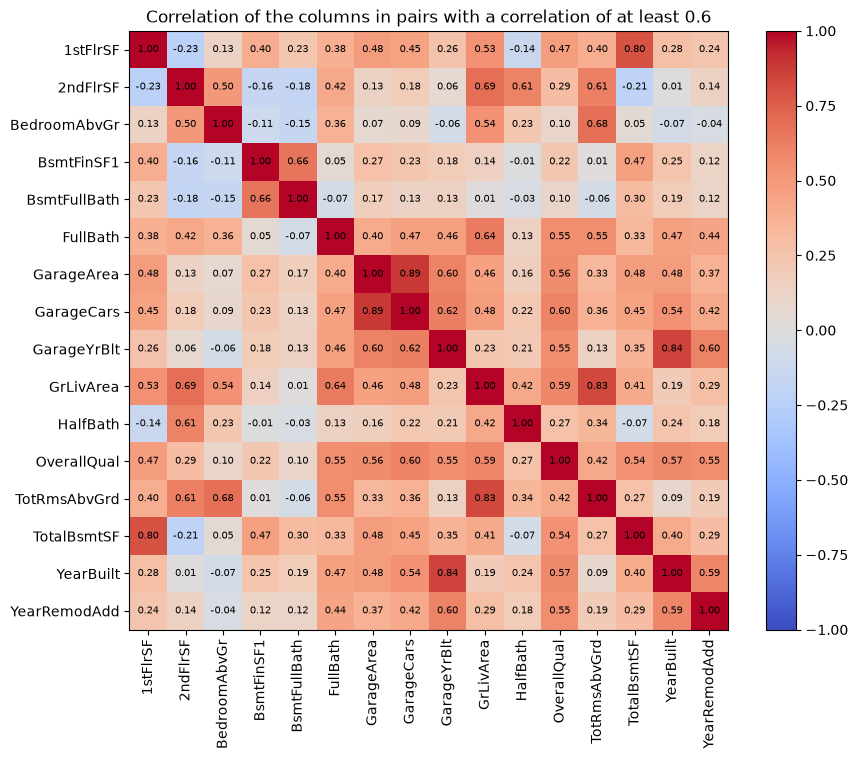

GrLivArea with its parts: {'1stFlrSF': 0.53, '2ndFlrSF': 0.69, 'LowQualFinSF': 0.14}
TotalBsmtSF with its parts: {'BsmtFinSF1': 0.47, 'BsmtFinSF2': 0.11, 'BsmtUnfSF': 0.44} 

Exterior2nd equals Exterior1st (spelling aside): 90.6%
GarageYrBlt equals YearBuilt, for houses with a garage: 78.9%
YearRemodAdd equals YearBuilt: 52.3%



,A,B,A predicts B,Most common B
0,Exterior1st,Exterior2nd,0.906,0.346
1,Exterior2nd,Exterior1st,0.911,0.353


In [46]:
# Screening for strong correlations between numeric columns. A strong correlation is a symptom of redundancy, not a definition of it.
correlation = numeric_features.corr()
pairs = correlation.where(np.triu(np.ones(correlation.shape), 1).astype(bool)).stack()
print("Pairs with a correlation of at least 0.7:", (pairs.abs() >= 0.7).sum(), ", Correlation at least 0.6:", (pairs.abs() >= 0.6).sum(), "\n")
display(pairs[pairs.abs() >= 0.6].sort_values(key=abs, ascending=False).round(2).rename("Correlation").to_frame())

# The columns in these pairs, as a heatmap.
involved = sorted(set(pairs[pairs.abs() >= 0.6].index.get_level_values(0)) | set(pairs[pairs.abs() >= 0.6].index.get_level_values(1)))
fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(correlation.loc[involved, involved], cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(involved)), involved, rotation=90)
ax.set_yticks(range(len(involved)), involved)
for i, row in enumerate(involved):
    for j, column in enumerate(involved):
        ax.text(j, i, f"{correlation.loc[row, column]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax)
ax.set_title("Correlation of the columns in pairs with a correlation of at least 0.6")
plt.tight_layout()
plt.show()

# The exact sums are hidden from a pairwise check: the correlation of each total with its parts.
print("GrLivArea with its parts:", correlation.loc["GrLivArea", ["1stFlrSF", "2ndFlrSF", "LowQualFinSF"]].round(2).to_dict())
print("TotalBsmtSF with its parts:", correlation.loc["TotalBsmtSF", ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]].round(2).to_dict(), "\n")

# Near duplicates: columns that are equal for most houses.
spelling = {"CmentBd": "CemntBd", "Wd Shng": "WdShing", "Brk Cmn": "BrkComm"}
garages = features[features["HasGarage"] == 1]
print(f"Exterior2nd equals Exterior1st (spelling aside): {(features['Exterior1st'] == features['Exterior2nd'].replace(spelling)).mean():.1%}")
print(f"GarageYrBlt equals YearBuilt, for houses with a garage: {(garages['GarageYrBlt'] == garages['YearBuilt']).mean():.1%}")
print(f"YearRemodAdd equals YearBuilt: {(features['YearRemodAdd'] == features['YearBuilt']).mean():.1%}\n")

# Categorical columns that determine one another: how well does the most common B in each level of A predict B?
categorical = features.select_dtypes(exclude="number")
informative = [column for column in categorical.columns if categorical[column].value_counts(normalize=True).iloc[0] < 0.95]
rows = []
for a in informative:
    for b in informative:
        if a != b and categorical[a].nunique() < 3 * categorical[b].nunique():
            predicted = categorical.groupby(a)[b].agg(lambda values: values.value_counts().iloc[0]).sum() / len(categorical)
            base = categorical[b].value_counts(normalize=True).iloc[0]
            if predicted >= 0.9 and predicted - base >= 0.15:
                rows.append({"A": a, "B": b, "A predicts B": predicted, "Most common B": base})
display(pd.DataFrame(rows).round(3))

In [47]:
# Groups of columns that measure one concept. Their correlations show whether the concept appears in the statistics.
groups = {
    "Bathrooms": ["FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"],
    "Outdoor area": ["WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"],
    "Years": ["YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold"],
    "Rooms": ["TotRmsAbvGrd", "BedroomAbvGr", "KitchenAbvGr", "GrLivArea"],
}
for name, columns in groups.items():
    print(name)
    display(features[columns].corr().round(2))

Bathrooms


,FullBath,HalfBath,BsmtFullBath,BsmtHalfBath
FullBath,1.00,0.13,-0.07,-0.05
HalfBath,0.13,1.00,-0.03,-0.01
BsmtFullBath,-0.07,-0.03,1.00,-0.15
BsmtHalfBath,-0.05,-0.01,-0.15,1.00


Outdoor area


,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch
WoodDeckSF,1.00,0.05,-0.13,-0.03,-0.07
OpenPorchSF,0.05,1.00,-0.09,-0.01,0.08
EnclosedPorch,-0.13,-0.09,1.00,-0.04,-0.08
3SsnPorch,-0.03,-0.01,-0.04,1.00,-0.03
ScreenPorch,-0.07,0.08,-0.08,-0.03,1.00


Years


,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold
YearBuilt,1.00,0.59,0.84,-0.01
YearRemodAdd,0.59,1.00,0.60,0.04
GarageYrBlt,0.84,0.60,1.00,-0.01
YrSold,-0.01,0.04,-0.01,1.00


Rooms


,TotRmsAbvGrd,BedroomAbvGr,KitchenAbvGr,GrLivArea
TotRmsAbvGrd,1.00,0.68,0.26,0.83
BedroomAbvGr,0.68,1.00,0.20,0.54
KitchenAbvGr,0.26,0.20,1.00,0.11
GrLivArea,0.83,0.54,0.11,1.00


##### Findings:
- Two exact linear dependencies exist: the 39 numeric columns have a rank of 37. Both are sums of areas. `GrLivArea` equals `1stFlrSF` + `2ndFlrSF` + `LowQualFinSF`, and `TotalBsmtSF` equals `BsmtFinSF1` + `BsmtFinSF2` + `BsmtUnfSF`, for every house.
- A pairwise correlation check cannot find them. `GrLivArea` correlates 0.53, 0.69 and 0.14 with its three parts, and `TotalBsmtSF` correlates 0.47, 0.11 and 0.44 with its three. A total is not strongly correlated with any one of its parts, but it is fully determined by all of them.
- Four columns repeat the presence information of another. `FireplaceQu` is `None` exactly when `Fireplaces` is 0, `PoolQC` when `PoolArea` is 0, and `GarageType` when `HasGarage` is 0 (a flag added by the cleaning). `MiscFeature` is `None` when `MiscVal` is 0 for 99.9% of houses. This was checked in the missing-data sections.
- Four numeric pairs have a correlation of at least 0.7: `GarageCars` and `GarageArea` (0.89), `YearBuilt` and `GarageYrBlt` (0.84), `GrLivArea` and `TotRmsAbvGrd` (0.83), and `TotalBsmtSF` and `1stFlrSF` (0.80). Ten more reach 0.6. Nearly all have a reason in the meaning of the columns: capacity and size, the dates of one house, an area and the rooms it holds, or a part and its total. The exception is `OverallQual` with `GarageCars` (0.60), which is an association between quality and size and not a redundancy.
- `Exterior2nd` repeats `Exterior1st` for 90.6% of houses once the spelling is matched, and they are the only pair of categorical columns where one predicts the other for 90% of houses. `GarageYrBlt` equals `YearBuilt` for 79% of garages, and `YearRemodAdd` equals `YearBuilt` for 52% of houses, which are those never remodelled.
- Some groups measure one concept but are almost uncorrelated. The four bathroom columns correlate between -0.15 and 0.13, and the five porch and deck columns between -0.13 and 0.08. They are related in meaning (a number of bathrooms, an amount of outdoor space) but not in the statistics, so a correlation threshold would never flag them.
- The year columns are the opposite. `YearBuilt`, `YearRemodAdd` and `GarageYrBlt` are strongly related (0.84 and 0.60) because they date the same house.

##### Decisions for feature engineering:
No column is changed here. These are the plans for the feature engineering step.

Exact sums:
- Models that break on exact collinearity, such as a plain linear regression, need one column fewer per relationship. Keep the totals `GrLivArea` and `TotalBsmtSF`, and drop `1stFlrSF` and `BsmtUnfSF`. Both can be recovered from the columns that stay, and dropping `1stFlrSF` also removes its 0.80 pair with `TotalBsmtSF`.
- Tree models and regularised models do not need this, so it is applied for the linear models.

Repeated presence information:
- Drop `HasGarage` when one-hot encoding `GarageType`, as it equals the `None` level.
- Do not add flags for a pool, a fireplace or a miscellaneous feature, as the existing columns already carry them.

Near duplicates:
- Replace `Exterior2nd` with a flag for a second material, which applies to the 9.4% of houses where it differs from `Exterior1st`, instead of a second category with 16 levels.
- Replace `GarageYrBlt` with `GarageAge`, as planned.
- Keep only one of `GarageCars` and `GarageArea` in linear models, chosen with the model. Keep `TotRmsAbvGrd` and `GrLivArea` unless a model suggests otherwise.

Groups for one concept:
- Replace the four bathroom columns with `TotalBathrooms` (`FullBath` + 0.5 × `HalfBath` + `BsmtFullBath` + 0.5 × `BsmtHalfBath`).
- Replace the year columns with ages: `HouseAge` (`YrSold` - `YearBuilt`), a remodelled flag or `RemodelAge`, and `GarageAge`.
- A total outdoor area is an option for the porch and deck columns, but the types may not act alike, so this is decided with the model.

These compactions mainly help linear models and interpretability. Regularisation such as lasso, or the importances of a tree model, can then decide among the columns that remain. That is done during modelling, with cross-validation.